## Финальный проект

#### *«Я чувствую себя как функция арктангенса, которая приближается к асимптоте.» — Теория большого взрыва*

Это финальный проект продуктового блока курса «Продуктовые метрики». За него можно получить максимум 60 баллов. 

**Дедлайны**   
Жесткий дедлайн: 25.10.2026 23:59 по МСК. 

После жесткого дедлайна работы не принимаются. 

**Правила сдачи**   
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание аннулируется у всех студентов, вне зависимости от того, кто у кого списал.    

**Использование ИИ**
- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета. 
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например final_project). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3. 

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.


Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/final_project_data.zip)

In [199]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import requests

from statsmodels.tsa.seasonal import STL
from scipy.stats import norm
from scipy.stats import t
import math

import plotly.graph_objects as go
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-dark')
%matplotlib inline

In [200]:
sns.set_theme(
    rc={'figure.figsize':(18,5),
        'legend.loc': 'best',
        'axes.labelcolor': (0, 0, 0, 0),
        'axes.labelsize': 0} 
        )

In [201]:
pd.set_option('display.float_format', '{:.4}'.format)

### Case Study. Улучшение сервиса доставки из ресторанов 🌮

**Легенда**   
Вы присоединились к продуктовой команде сервиса доставки из ресторанов в роли аналитика. Близится планирование следующего квартала, пора готовить бэклог инициатив. Продакт-менеджер особенно беспокоится об удовлетворенности пользователей — за последний месяц выросло число отмен и жалоб на задержки.

Вам поставлена задача: провести исследование текущих значений метрик, выдвинуть гипотезу о проблеме и предложить её решение.

In [202]:
df = pd.read_csv('data/final_project_delivery.csv')

df.head()

,order_id,order_time,delivery_time,status,cancellation_reason,order_value,delivery_fee,estimated_delivery_time_min,time_to_assign_courier_min,actual_preparation_time_min,travel_time_min,delivery_distance_km,promotion_used,platform,city_region,user_id,user_segment
0,257,2022-11-01 00:01:46,2022-11-01 00:21:52,delivered,NaN,25.73,2.09,27.0,10.2,15.1,5.0,3.48,no,Android,Belem,5737,returning
1,165,2022-11-01 00:06:07,2022-11-01 00:27:01,delivered,NaN,22.0,0.77,13.0,9.0,15.9,5.0,1.29,no,iOS,Parque das Nacoes,4095,new
2,343,2022-11-01 21:07:01,2022-11-01 21:40:07,delivered,NaN,29.9,3.53,44.0,10.6,15.4,15.1,5.88,no,iOS,Parque das Nacoes,15991,returning
3,904,2022-11-01 00:06:48,2022-11-01 00:36:42,delivered,NaN,40.49,2.02,27.0,3.7,16.0,13.9,3.36,no,Android,Alfama,1773,returning
4,555,2022-11-01 00:09:58,2022-11-01 00:57:22,delivered,NaN,35.75,3.48,39.0,5.2,12.3,35.1,5.8,no,iOS,Baixa,5203,returning


Описание данных:

- order_id — уникальный идентификатор заказа
- order_time — timestamp создания заказа
- delivery_time – timestamp доставки заказа
- status — статус заказа, принимает 2 значения: delivered и cancelled
- cancellation_reason — причина отмены заказа: Cancelled by user (отменена пользователем) и No courier available (нет доступных курьеров)
- order_value — стоимость заказа
- delivery_fee — стоимость доставки
- estimated_delivery_time_min — прогнозное время доставки
- time_to_assign_courier_min — время до назначения курьера
- actual_preparation_time_min — время приготовления заказа рестораном
- travel_time_min — суммарное время на дорогу курьера до ресторана и до конечного пользователя
- delivery_distance_km — расстояние от адреса доставки до адреса ресторана
- promotion_used — был ли заказ совершен с использованием промокода или акции
- platform — платформа, с которой совершен заказ
- city_region — район города, в который планируется доставка
- user_id — уникальный идентификатор пользователя, сделавшего заказ
- user_segment — сегмент пользователя (новый или вернувшийся)    

### Часть 1. Исследование

#### 1. Динамика основных метрик — 3 балла
Рассчитайте и визуализируйте по дням:
- Число заказов, число доставленных заказов (статус delivered);
- Completion Rate (Доставленные заказы / Все заказы), Cancellation Rate (Отмененные заказы / Все заказы);
- Среднее и медианное время доставки в минутах (рассчитывается как разница между delivery_time и order_time), средний чек заказа, среднюю стоимость доставки.

Сделайте выводы:
- Есть ли выраженный тренд?
- Может быть какие-то дни кажутся подозрительными на предмет аномалий?

In [203]:
df['order_date']=pd.to_datetime(df['order_time']).dt.date
df['delivery_date']=pd.to_datetime(df['delivery_time']).dt.date
df['order_time']=pd.to_datetime(df['order_time'])
df['delivery_time']=pd.to_datetime(df['delivery_time'])
df['order_month']=pd.to_datetime(df['order_time']).dt.month
df['order_month_name']=pd.to_datetime(df['order_time']).dt.month_name()
df=df.sort_values(by='order_time')

##### 1.1 Количество всех заказов, количество доставленных заказов.

In [204]:
orders=df.pivot_table(index='order_date', columns='status', values='order_id', aggfunc='count', margins=True, margins_name='total').iloc[:-1,:]
orders.head()

status,cancelled,delivered,total
order_date,,,
2022-11-01,46,963,1009
2022-11-02,41,952,993
2022-11-03,67,925,992
2022-11-04,72,1463,1535
2022-11-05,68,1446,1514


In [205]:
def simple_viz(df, title, legend_spot='upper left'):
    sns.lineplot(data=df)
    plt.xlabel('')
    plt.title(title)
    plt.legend(loc=legend_spot)
    plt.show()

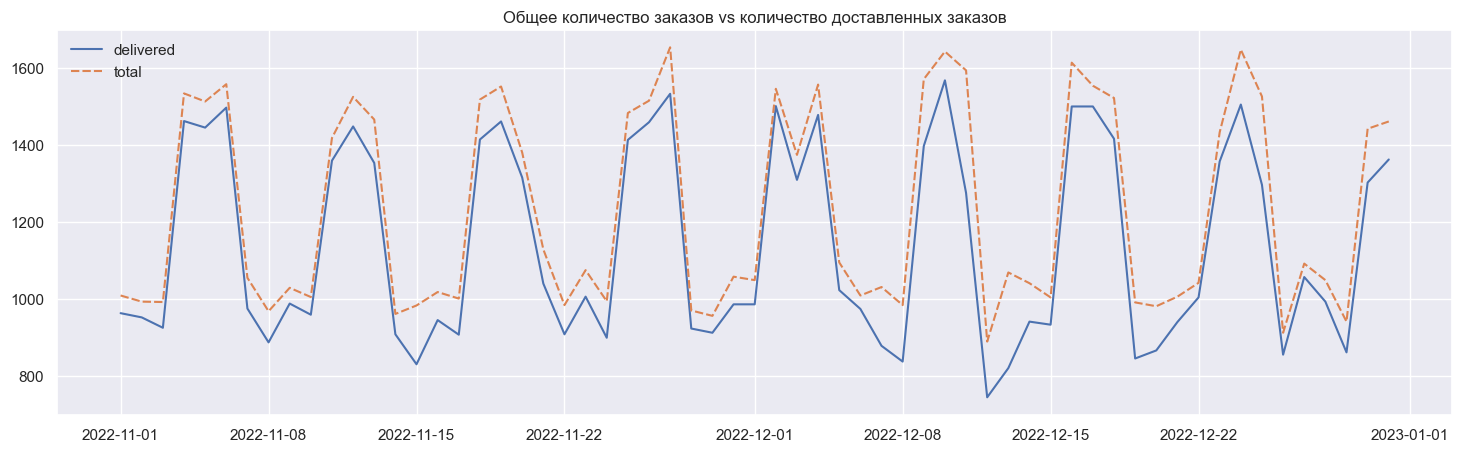

In [206]:
simple_viz(orders.drop(columns='cancelled'),'Общее количество заказов vs количество доставленных заказов')

##### 1.2 Completion Rate, Cancellation Rate

In [207]:
orders['completion_rate']=orders['delivered']/orders['total']
orders['cancellation_rate']=orders['cancelled']/orders['total']
orders.head(3)

status,cancelled,delivered,total,completion_rate,cancellation_rate
order_date,,,,,
2022-11-01,46,963,1009,0.9544,0.04559
2022-11-02,41,952,993,0.9587,0.04129
2022-11-03,67,925,992,0.9325,0.06754


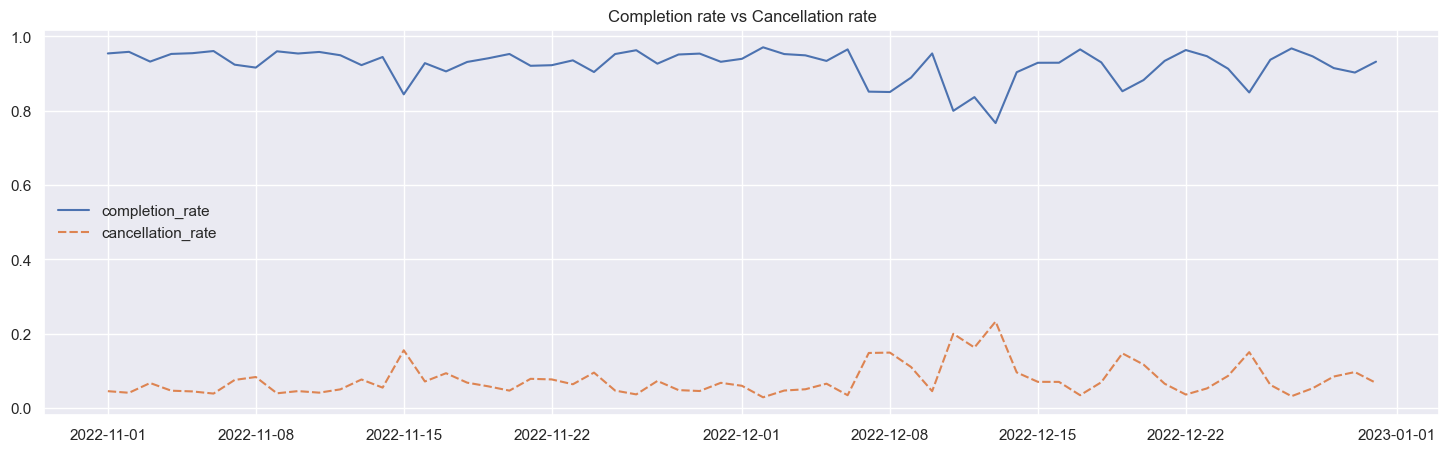

In [208]:
simple_viz(orders[['completion_rate','cancellation_rate']],'Completion rate vs Cancellation rate', legend_spot='center left')

##### 1.3 Среднее и медианное время доставки в минутах, средний чек заказа, средняя  стоимость доставки.

In [209]:
df['order_delivery_time_min']=(df['delivery_time']-df['order_time']).dt.total_seconds()//60
orders_delivery_time=df[df['order_delivery_time_min'].notna()].pivot_table(index='order_date', values='order_delivery_time_min', aggfunc=('mean', 'median'))
orders_delivery_time.head(3)

,mean,median
order_date,,
2022-11-01,31.07,30.0
2022-11-02,31.26,29.0
2022-11-03,33.92,32.0


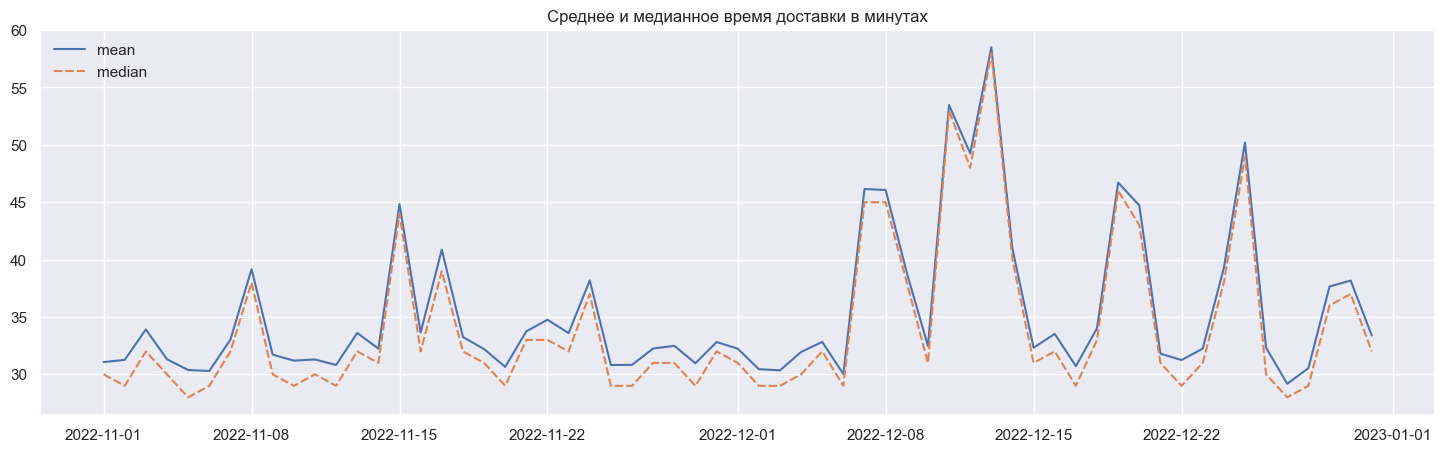

In [210]:
simple_viz(orders_delivery_time[['mean', 'median']], "Среднее и медианное время доставки в минутах")

In [211]:
#так как не сказано по каким заказам считать среднюю стоимость заказа и доставки, то считаю только по выполненным:
order_daily_revenue=df[df['delivery_date'].notna()].pivot_table(index='order_date', values=('order_value', 'delivery_fee'), aggfunc=('mean'))
order_daily_revenue.head(3)

,delivery_fee,order_value
order_date,,
2022-11-01,2.288,25.07
2022-11-02,2.403,25.4
2022-11-03,2.374,25.16


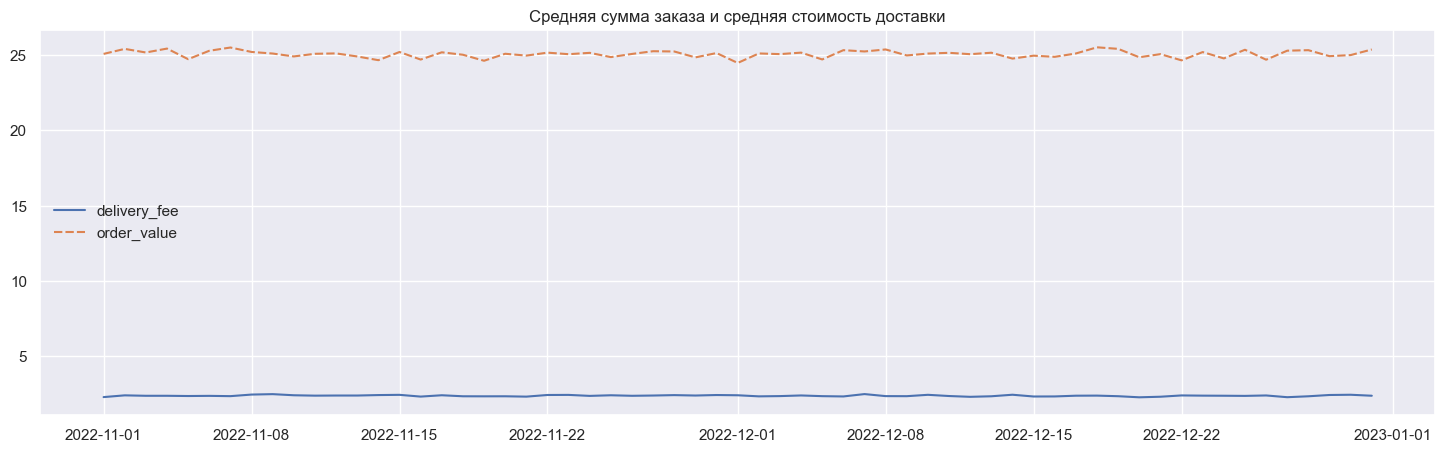

In [212]:
simple_viz(order_daily_revenue, 'Средняя сумма заказа и средняя стоимость доставки', legend_spot='center left')

**Выводы:** <br>
**- Ярковыраженных трендов я не увидела, все метрики стабильны. Заметна сезонность в метриках общего количества заказов и доставленных заказов.**<br>
**- Выделяются пики в среднем и медианном времени доставки заказов в декабре. Второй, самый высокий пик, выглядит аномальным.**

#### 2. Выявление аномалий — 3 балла
Проверьте построенные дневные ряды следующих метрик на аномальность:
- Число заказов, число доставленных заказов;
- Completion Rate, Cancellation Rate;
- Время доставки (среднее и медиана).

Для метрик, в которых визуально заметна недельная сезонность (абсолютные метрики), используйте STL-разложение + 3σ, для других — просто 3σ (вы проводите ретроспективный анализ, а не имитируете онлайн-проверку, не забывайте об этом в реализации).

Дайте короткий комментарий по результатам проверки.

среднее и стандартное отклонение вычисляются по всему историческому ряду

In [213]:
def get_anomaly_3_sigma(df, metric):
    if metric!='resid':
        df=df[metric].copy()
    else: 
        df=df.copy()
    mean = df.mean()
    std = df.std()

    lcl = mean - 3 * std
    ulc = mean + 3 * std
    
    df=df.reset_index()
    df['is_anomaly'] = ((df[metric] <  lcl) |(df[metric] > ulc))
    return df

In [214]:
completion_rate_3_sigma=get_anomaly_3_sigma(orders, 'completion_rate')
completion_rate_3_sigma.query('is_anomaly==True')

,order_date,completion_rate,is_anomaly
42,2022-12-13,0.7671,True


In [215]:
cancellation_rate_3_sigma=get_anomaly_3_sigma(orders, 'cancellation_rate')
cancellation_rate_3_sigma.query('is_anomaly==True')

,order_date,cancellation_rate,is_anomaly
42,2022-12-13,0.2329,True


In [216]:
get_anomaly_3_sigma(orders_delivery_time, 'mean').query('is_anomaly==True')

,order_date,mean,is_anomaly
42,2022-12-13,58.5,True


In [217]:
get_anomaly_3_sigma(orders_delivery_time, 'median').query('is_anomaly==True')

,order_date,median,is_anomaly
42,2022-12-13,58.0,True


In [218]:
def get_stl(df, metric, period=7):
    ts = df[metric]
    stl = STL(ts, period=period, robust=True)
    stl_result = stl.fit()

    return stl_result

In [219]:
def get_stl_viz(stl_result, metric):
    trend = stl_result.trend
    seasonal = stl_result.seasonal
    resid = stl_result.resid
    observed = stl_result.observed

    fig, axes = plt.subplots(4, 1, figsize=(12, 6), sharex=True)
    
    axes[0].plot(observed, label='Observed')
    axes[0].legend(loc='upper left')
    
    axes[1].plot(trend, color='orange', label='Trend')
    axes[1].legend(loc='upper left')
    
    axes[2].plot(seasonal, color='green', label='Seasonal')
    axes[2].legend(loc='upper left')
    
    axes[3].plot(resid, color='red', label='Residuals')
    axes[3].legend(loc='upper left')

    fig.suptitle(f'{metric} STL', fontsize=14)
    plt.tight_layout()
    plt.show()

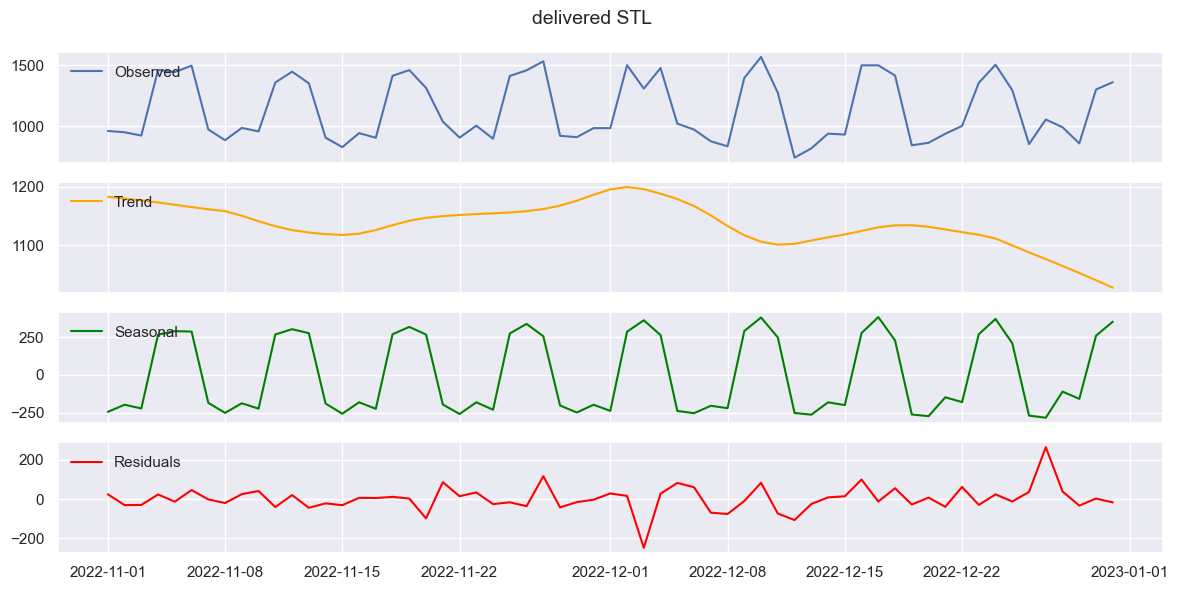

In [220]:
delivered_orders_stl=get_stl(orders, 'delivered')
get_stl_viz(delivered_orders_stl, 'delivered')

In [221]:
delivered_orders_anomaly=get_anomaly_3_sigma(delivered_orders_stl.resid, 'resid')
delivered_orders_anomaly.query('is_anomaly==True')

,order_date,resid,is_anomaly
32,2022-12-03,-247.5,True
56,2022-12-27,264.0,True


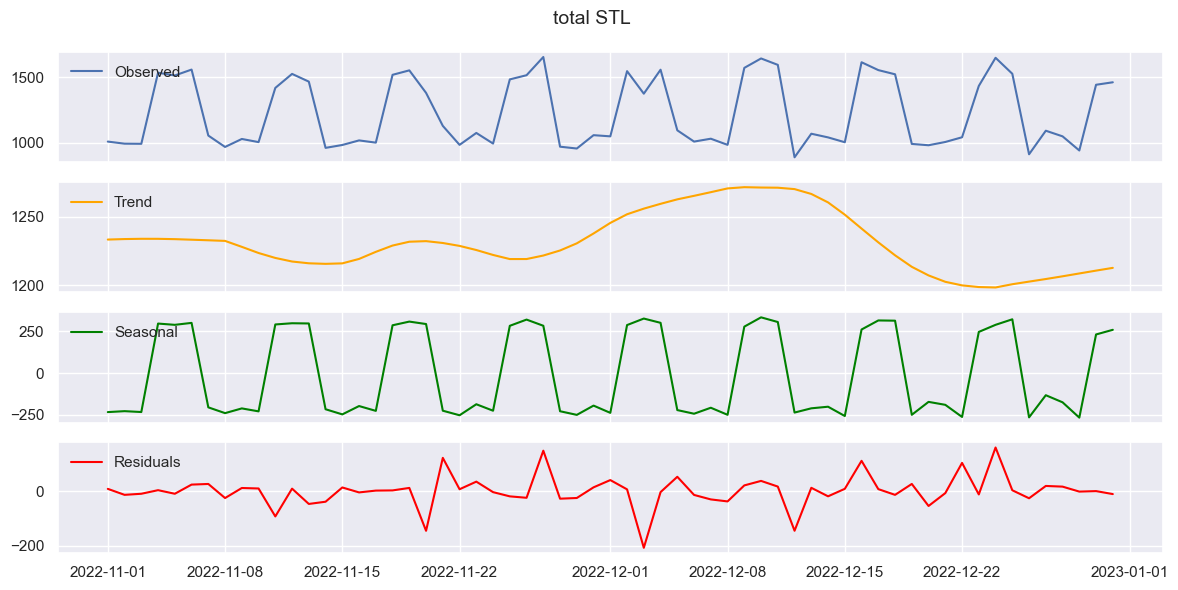

In [222]:
total_orders_stl=get_stl(orders, 'total')
get_stl_viz(total_orders_stl, 'total')

In [223]:
total_orders_anomaly=get_anomaly_3_sigma(total_orders_stl.resid, 'resid')
total_orders_anomaly.query('is_anomaly==True')

,order_date,resid,is_anomaly
32,2022-12-03,-208.3,True


**Выводы** <br>
**Проверки показателей работы сервиса, а именно доли доставленных/отменных заказов, а также среднее/медианное время доставки, показали, что день 2022-12-13 является аномальным. Показатели заказов также показывают на аномальные даты, но другие, в которых покупатели проявляли себя не как обычно, например, 2022-12-03 заказывали меньше обычного.**

#### 3. Поиск причин аномального поведения (шаг 1) — 3 балла
Разложим метрики, в которых обнаружены аномалии, на составляющие.

Визуализируйте:
- Отмены в разрезе причин (абсолютная метрика);
- Длительность этапов, из которых складывается итоговая продолжительность доставки (time_to_assign_courier_min, actual_preparation_time_min, travel_time_min). Берите среднее или медиану на ваш выбор.

Есть ли какие-нибудь закономерности?

In [224]:
cancelled_orders=df.query('status=="cancelled"').groupby(['order_date','cancellation_reason'], as_index=False).agg(orders_count=('order_id', 'count'))
cancelled_orders.head(3)

,order_date,cancellation_reason,orders_count
0,2022-11-01,Cancelled by user,38
1,2022-11-01,No courier available,8
2,2022-11-02,Cancelled by user,35


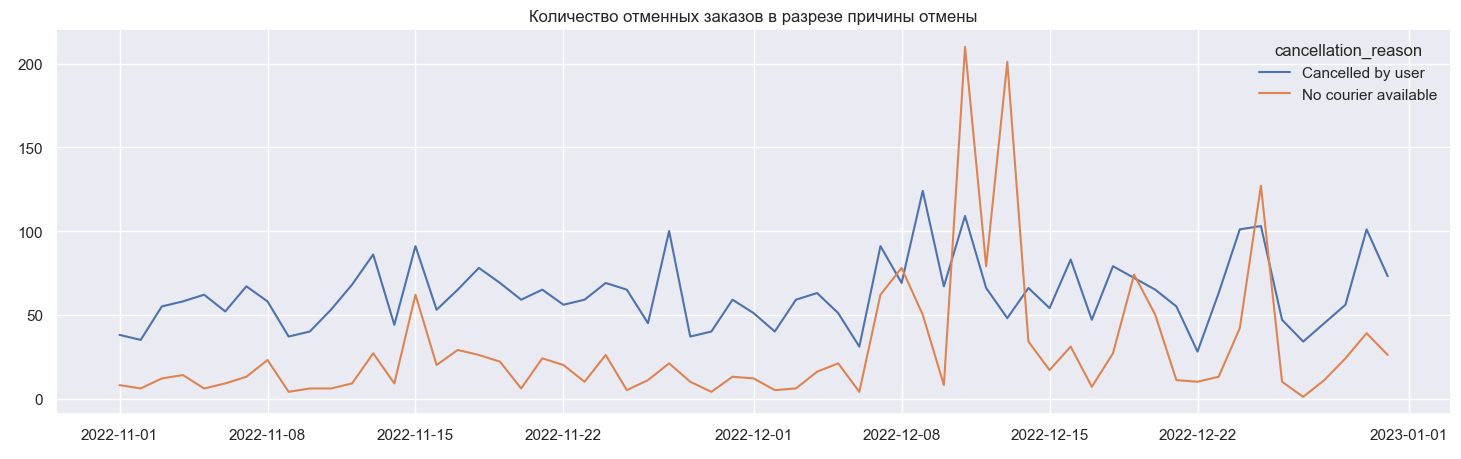

In [225]:
sns.lineplot(data=cancelled_orders, x='order_date', y='orders_count', hue='cancellation_reason')
plt.title('Количество отменных заказов в разрезе причины отмены')
plt.show()

In [226]:
#этапы, из которых состоит время заказа
detailed_delivery_time= df.groupby('order_date', as_index=False).agg(time_to_assign_courier=('time_to_assign_courier_min', 'mean'), actual_preparation_time=('actual_preparation_time_min', 'mean'), 
                                                                     travel_time_min=('travel_time_min', 'mean')).melt(id_vars='order_date', var_name='metric', value_name='value')

In [227]:
detailed_delivery_time.head(3)

,order_date,metric,value
0,2022-11-01,time_to_assign_courier,6.677
1,2022-11-02,time_to_assign_courier,6.582
2,2022-11-03,time_to_assign_courier,6.463


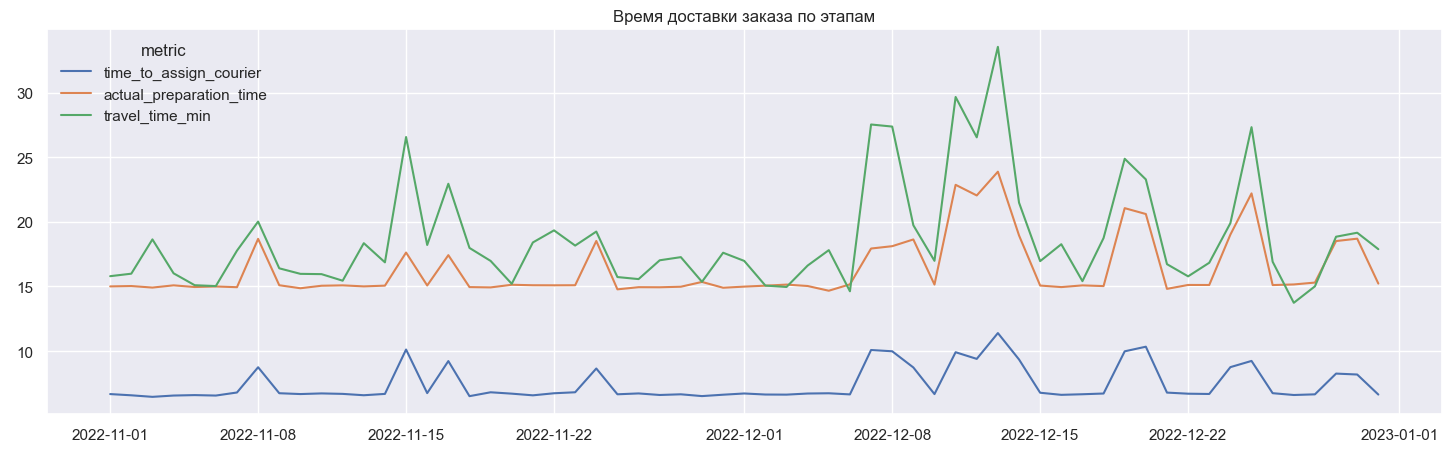

In [228]:
sns.lineplot(data=detailed_delivery_time, x='order_date', y='value', hue='metric')
plt.title('Время доставки заказа по этапам')
plt.show()

**Можно отметить, что в дни, когда назначение курьера на заказ происходит дольше обычного, доля заказов по причине "no courier available" также выше. В эти же дни и сама доставка осуществлялась дольше обычного.**<br>

#### 4. Поиск причин аномального поведения (шаг 2) — 3 балла
Постройте динамику метрик, в которых обнаружены аномалии, по базовым срезам (можете выбрать что-то одно: Completion Rate или Cancellation Rate, среднее время доставки или медиана времени доставки):
- платформа (iOS, Android);
- район адреса доставки;
- сегмент пользователя (новые / повторные);
- признак промо акции.

Выделяется ли какой-то сегмент, где аномалия выражена сильнее?

In [229]:
cancelled_by_platform=df.query('status=="cancelled"').groupby(['order_date','platform'], as_index=False).agg(orders_count=('order_id', 'count'))
total_by_platform=df.groupby(['order_date','platform'], as_index=False).agg(orders_count=('order_id', 'count'))
cancelled_by_platform['cancellation_rate']=cancelled_by_platform['orders_count']/total_by_platform['orders_count']
cancelled_by_platform.head(3)

,order_date,platform,orders_count,cancellation_rate
0,2022-11-01,Android,15,0.03261
1,2022-11-01,iOS,31,0.05647
2,2022-11-02,Android,15,0.03341


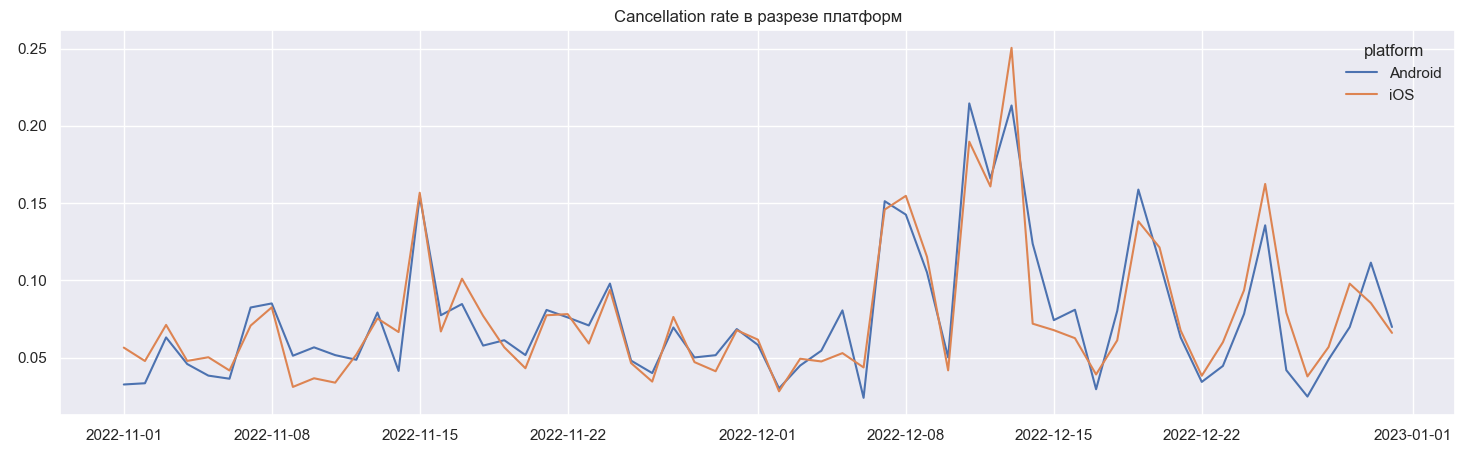

In [230]:
sns.lineplot(data=cancelled_by_platform, x='order_date', y='cancellation_rate', hue='platform')
plt.title('Cancellation rate в разрезе платформ')
plt.show()

In [231]:
cancelled_by_region=df.query('status=="cancelled"').groupby(['order_date','city_region'], as_index=False).agg(orders_count=('order_id', 'count'))
total_by_region=df.groupby(['order_date','city_region'], as_index=False).agg(orders_count=('order_id', 'count'))
cancelled_by_region['cancellation_rate']=cancelled_by_region['orders_count']/total_by_region['orders_count']
cancelled_by_region.head(3)

,order_date,city_region,orders_count,cancellation_rate
0,2022-11-01,Alfama,12,0.04819
1,2022-11-01,Baixa,12,0.05195
2,2022-11-01,Belem,14,0.05224


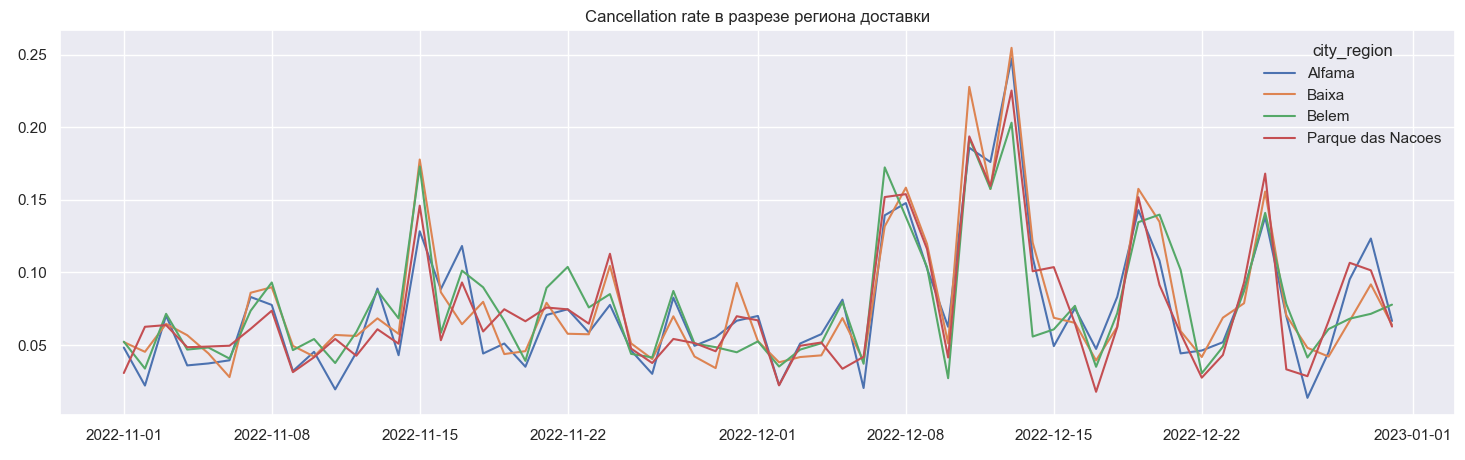

In [232]:
sns.lineplot(data=cancelled_by_region, x='order_date', y='cancellation_rate', hue='city_region')
plt.title('Cancellation rate в разрезе региона доставки')
plt.show()

In [233]:
cancelled_by_segment=df.query('status=="cancelled"').groupby(['order_date','user_segment'], as_index=False).agg(orders_count=('order_id', 'count'))
total_by_segment=df.groupby(['order_date','user_segment'], as_index=False).agg(orders_count=('order_id', 'count'))
cancelled_by_segment['cancellation_rate']=cancelled_by_segment['orders_count']/total_by_segment['orders_count']
cancelled_by_segment.head(3)

,order_date,user_segment,orders_count,cancellation_rate
0,2022-11-01,new,5,0.03401
1,2022-11-01,returning,41,0.04756
2,2022-11-02,new,7,0.04965


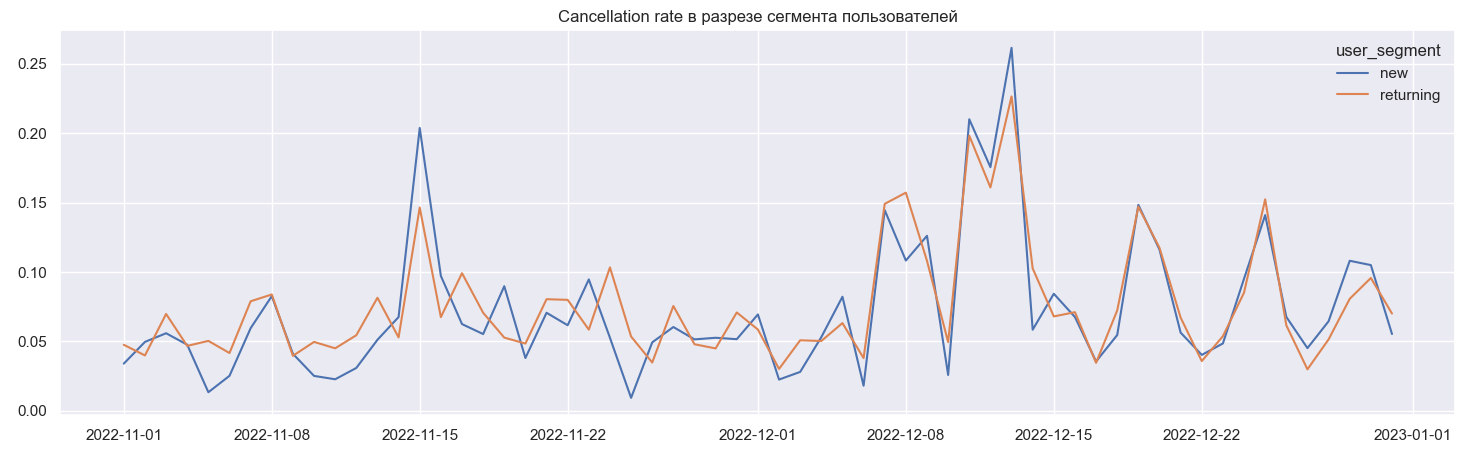

In [234]:
sns.lineplot(data=cancelled_by_segment, x='order_date', y='cancellation_rate', hue='user_segment')
plt.title('Cancellation rate в разрезе сегмента пользователей')
plt.show()

In [235]:
cancelled_by_promo=df.query('status=="cancelled"').groupby(['order_date','promotion_used'], as_index=False).agg(orders_count=('order_id', 'count'))
total_by_promo=df.groupby(['order_date','promotion_used'], as_index=False).agg(orders_count=('order_id', 'count'))
cancelled_by_promo['cancellation_rate']=cancelled_by_promo['orders_count']/total_by_promo['orders_count']
cancelled_by_promo.head(3)

,order_date,promotion_used,orders_count,cancellation_rate
0,2022-11-01,no,42,0.04526
1,2022-11-01,yes,4,0.04938
2,2022-11-02,no,37,0.0412


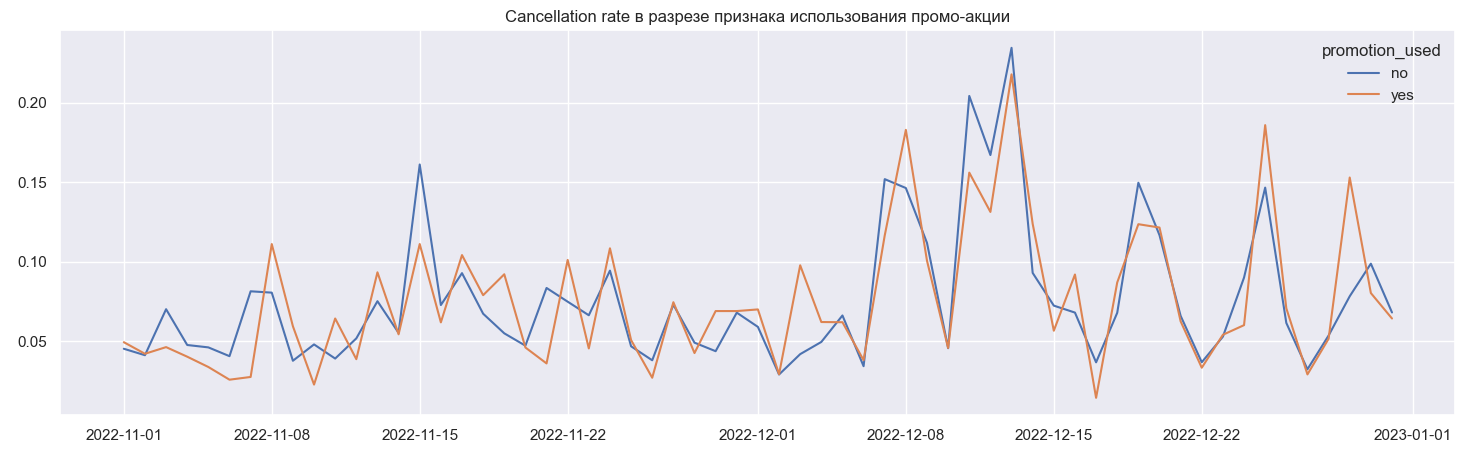

In [236]:
sns.lineplot(data=cancelled_by_promo, x='order_date', y='cancellation_rate', hue='promotion_used')
plt.title('Cancellation rate в разрезе признака использования промо-акции')
plt.show()

In [237]:
df.head()

,order_id,order_time,delivery_time,status,cancellation_reason,order_value,delivery_fee,estimated_delivery_time_min,time_to_assign_courier_min,actual_preparation_time_min,...,promotion_used,platform,city_region,user_id,user_segment,order_date,delivery_date,order_month,order_month_name,order_delivery_time_min
0,257,2022-11-01 00:01:46,2022-11-01 00:21:52,delivered,NaN,25.73,2.09,27.0,10.2,15.1,...,no,Android,Belem,5737,returning,2022-11-01,2022-11-01,11,November,20.0
1,165,2022-11-01 00:06:07,2022-11-01 00:27:01,delivered,NaN,22.0,0.77,13.0,9.0,15.9,...,no,iOS,Parque das Nacoes,4095,new,2022-11-01,2022-11-01,11,November,20.0
3,904,2022-11-01 00:06:48,2022-11-01 00:36:42,delivered,NaN,40.49,2.02,27.0,3.7,16.0,...,no,Android,Alfama,1773,returning,2022-11-01,2022-11-01,11,November,29.0
4,555,2022-11-01 00:09:58,2022-11-01 00:57:22,delivered,NaN,35.75,3.48,39.0,5.2,12.3,...,no,iOS,Baixa,5203,returning,2022-11-01,2022-11-01,11,November,47.0
5,524,2022-11-01 00:10:28,2022-11-01 00:40:16,delivered,NaN,33.92,1.48,20.0,5.3,12.9,...,no,Android,Baixa,6727,returning,2022-11-01,2022-11-01,11,November,29.0


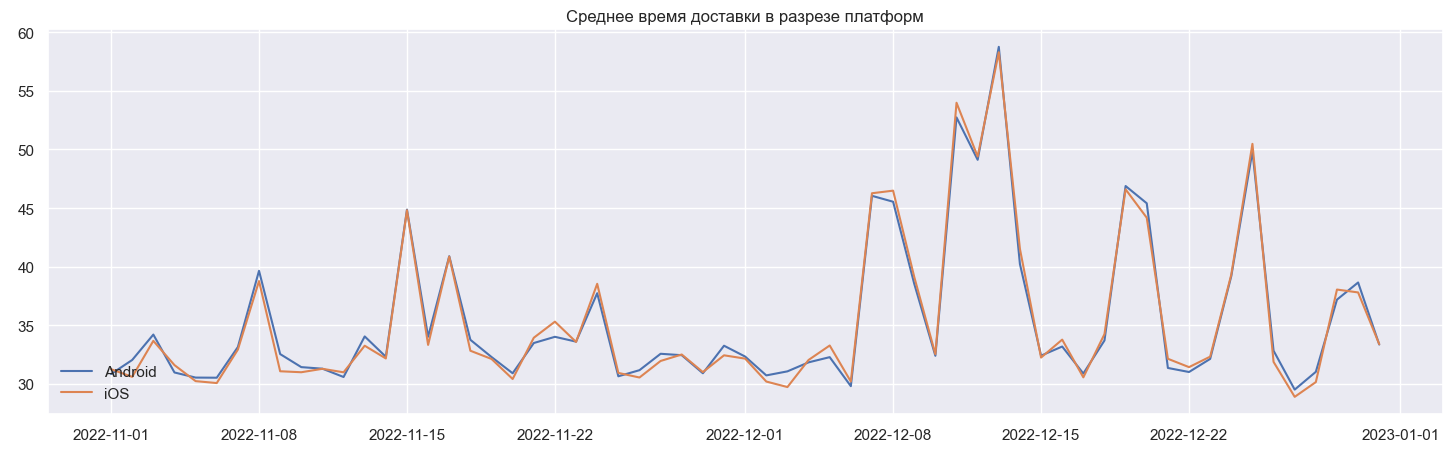

In [238]:
sns.lineplot(data=df.query('delivery_time.notna()').groupby(['order_date','platform'], as_index=False).agg(mean_orders_delivery_time=('order_delivery_time_min', 'mean')), 
             x='order_date', y='mean_orders_delivery_time', hue='platform')
plt.title('Среднее время доставки в разрезе платформ')
plt.legend(loc='lower left')
plt.show()

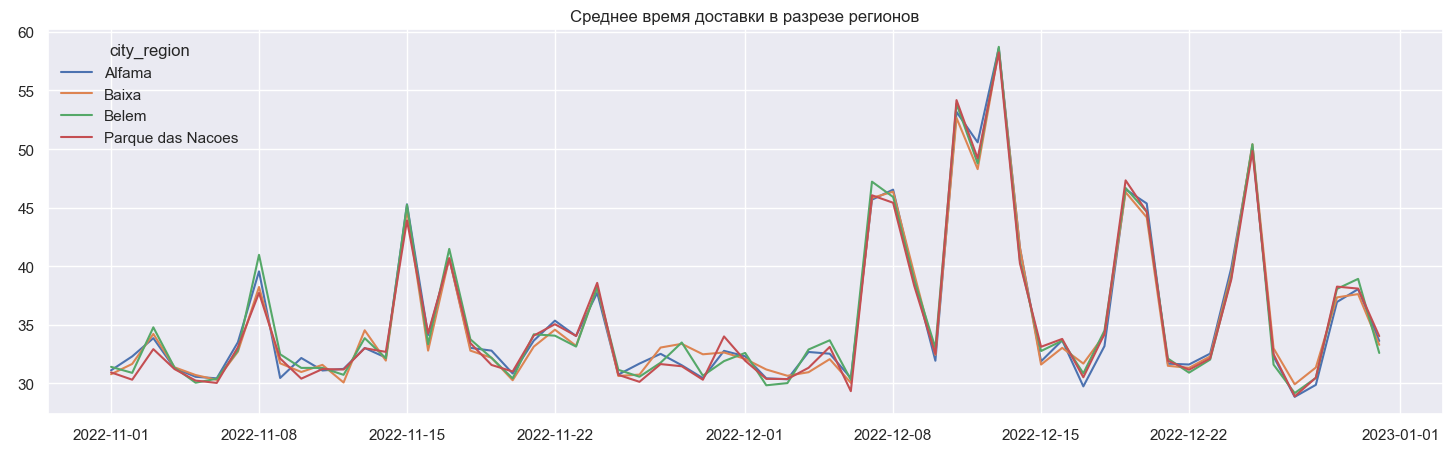

In [239]:
sns.lineplot(data=df.query('delivery_time.notna()').groupby(['order_date','city_region'], as_index=False).agg(mean_orders_delivery_time=('order_delivery_time_min', 'mean')), 
             x='order_date', y='mean_orders_delivery_time', hue='city_region')
plt.title('Среднее время доставки в разрезе регионов')
plt.show()

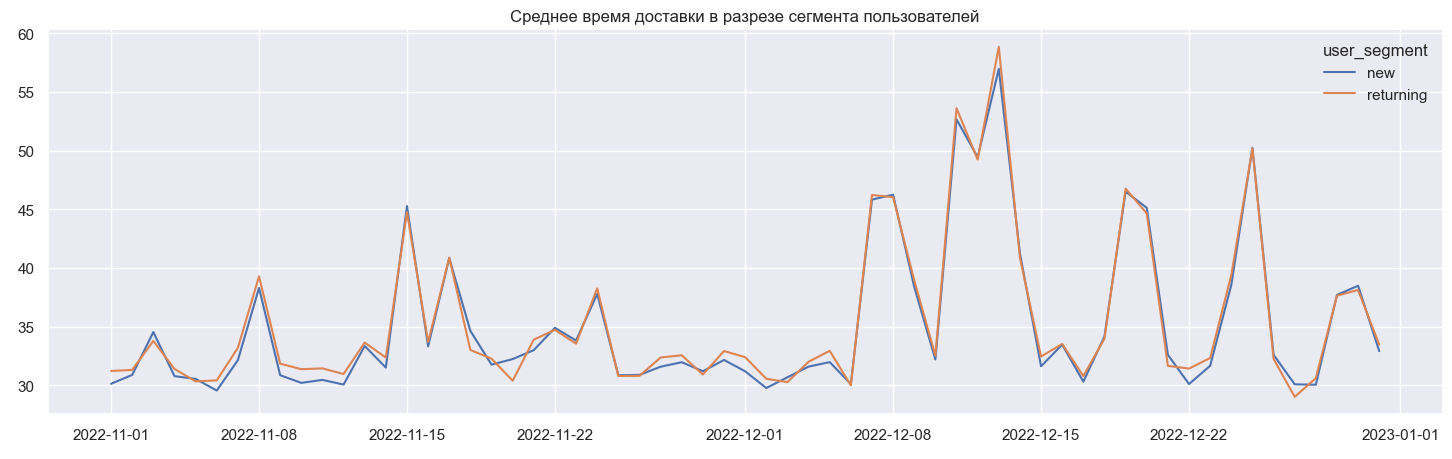

In [240]:
sns.lineplot(data=df.groupby(['order_date','user_segment'], as_index=False).agg(mean_orders_delivery_time=('order_delivery_time_min', 'mean')), x='order_date', y='mean_orders_delivery_time', hue='user_segment')
plt.title('Среднее время доставки в разрезе сегмента пользователей')
plt.show()

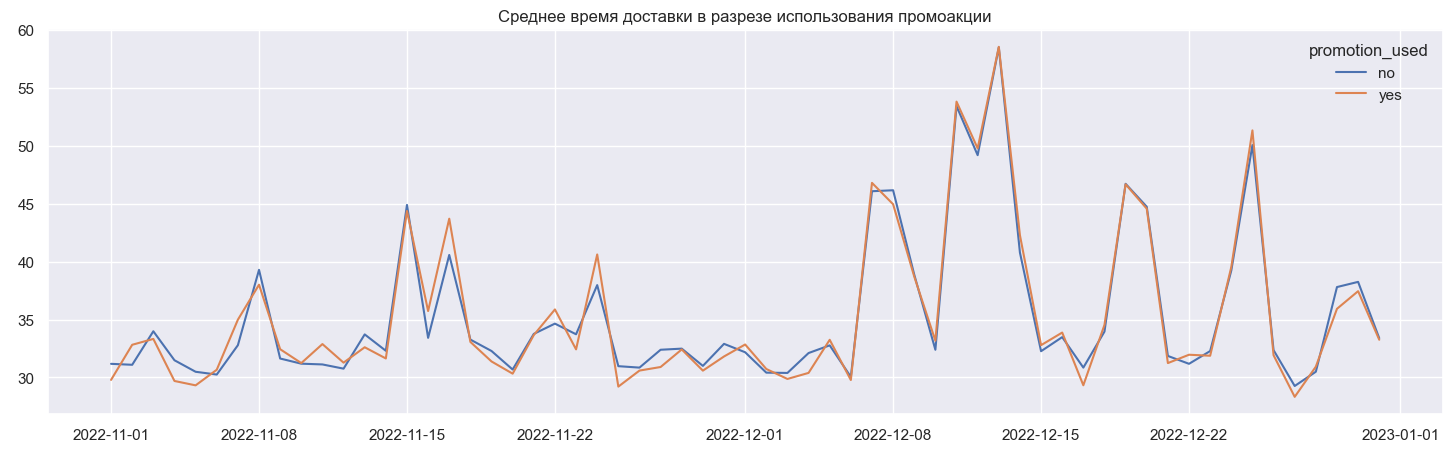

In [241]:
sns.lineplot(data=df.groupby(['order_date','promotion_used'], as_index=False).agg(mean_orders_delivery_time=('order_delivery_time_min', 'mean')), x='order_date', y='mean_orders_delivery_time', hue='promotion_used')
plt.title('Среднее время доставки в разрезе использования промоакции')
plt.show()

**Выводы**<br>
**На графиках нет срезов, которые бы объясняли изменение метрики. Метрики в представленных сегмента изменялись почти синхронно.** 

#### 5. Поиск причин аномального поведения (шаг 3) — 3 балла

Постройте динамику структуры заказов в разрезе сегментов:
- доля заказов по платформам;
- доля заказов по регионам города;
- доля заказов по сегменту пользователя;
- доля заказов по признаку промо акции.

Сравните даты аномалий с динамикой долей. Может ли изменение структуры объяснить падение метрик?

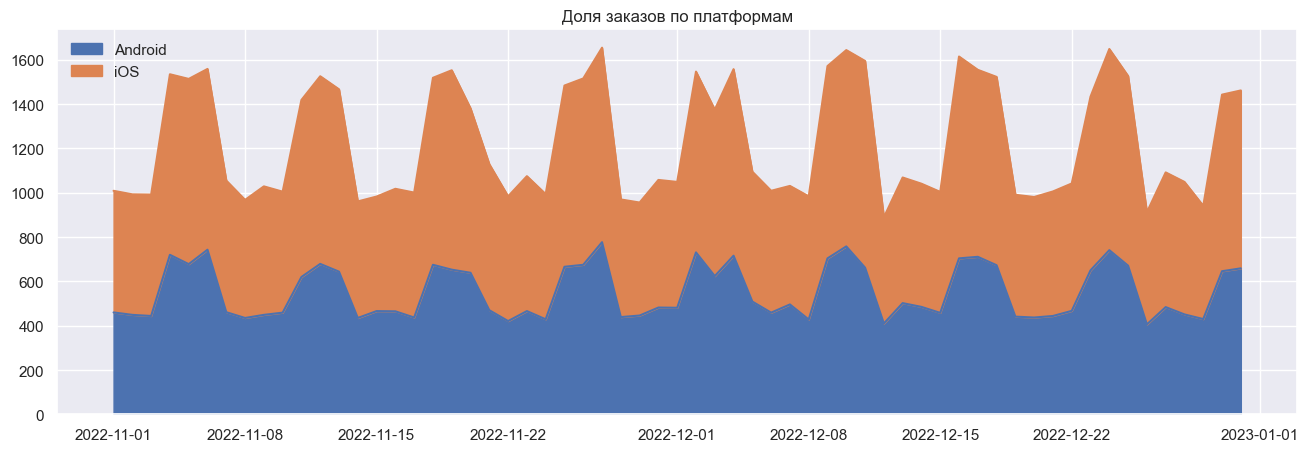

In [242]:
df.pivot_table(index='order_date', columns='platform', values='order_id', aggfunc='count').plot.area(figsize=(16,5))
plt.legend(loc='upper left')
plt.title('Доля заказов по платформам')
plt.show()

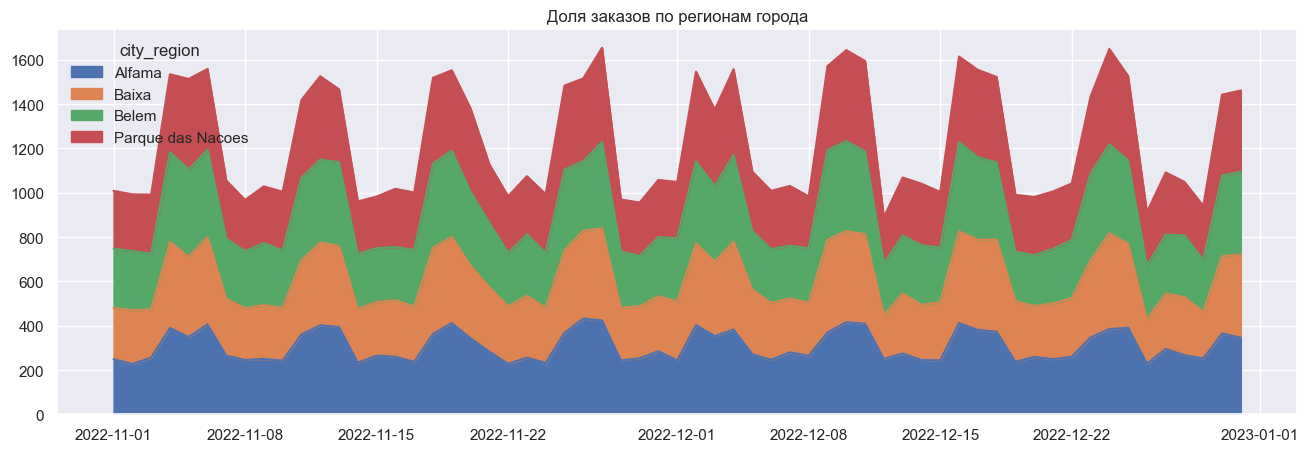

In [243]:
df.pivot_table(index='order_date', columns='city_region', values='order_id', aggfunc='count').plot.area(figsize=(16,5))
plt.title('Доля заказов по регионам города')
plt.show()

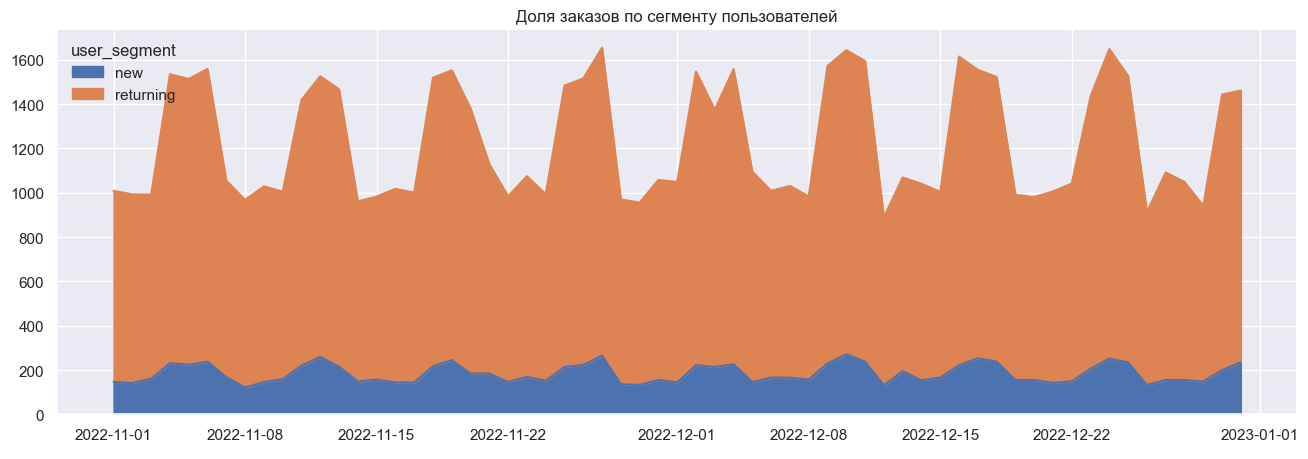

In [244]:
df.pivot_table(index='order_date', columns='user_segment', values='order_id', aggfunc='count').plot.area(figsize=(16,5))
plt.title('Доля заказов по сегменту пользователей')
plt.show()

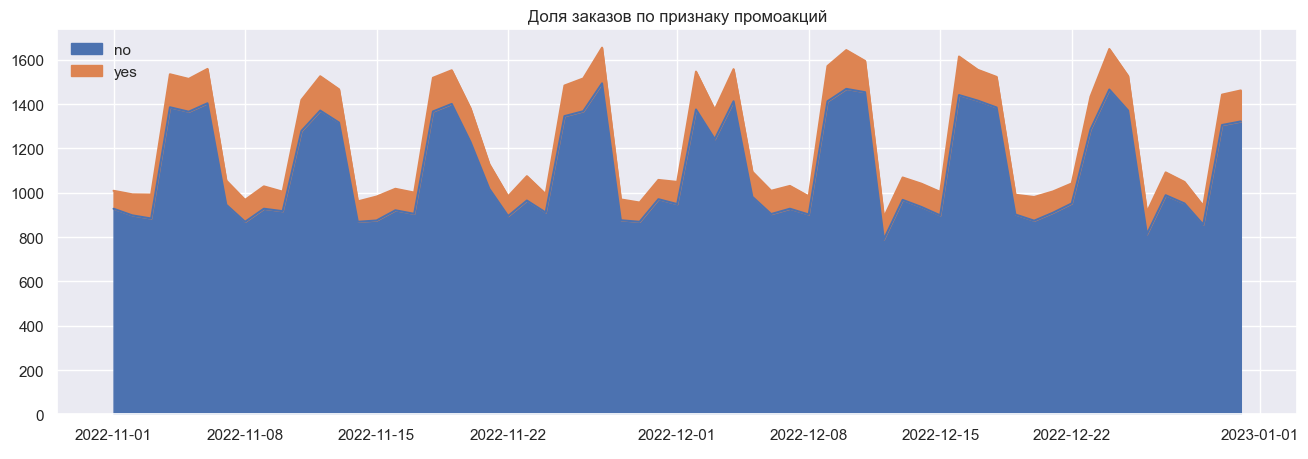

In [245]:
df.pivot_table(index='order_date', columns='promotion_used', values='order_id', aggfunc='count').plot.area(figsize=(16,5))
plt.title('Доля заказов по признаку промоакций')
plt.legend(loc='upper left')
plt.show()

**На мой взгляд структура заказов также не объясняет аномалии в метриках.**

#### 6. Поиск причин аномального поведения (шаг 4) — 3 балла
Разложение метрик на срезы не принесло результатов. Может быть причина аномалий лежит вне продукта?

Получите данные о погоде по API за весь анализируемый период по дням. Для этого используйте [Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api?daily=temperature_2m_mean,wind_speed_10m_max,precipitation_sum) от Open-Meteo (регистрация и получение ключа не требуется, по ссылке есть пример запроса на Python).

- Для координат выгрузки возьмите: latitude: 38.736946, longitude: -9.142685;
- Timezone — auto;
- daily значения temperature_2m_mean, precipitation_sum, wind_speed_10m_max.

Соберите датасет с колонками: день, средняя температура воздуха, максимальная скорость ветра, суммарное количество осадков.

In [246]:
# your code is here
daily_weather=pd.read_csv('daily_weather.csv', index_col=0)
daily_weather['date']=pd.to_datetime(daily_weather['date']).dt.date
daily_weather=daily_weather.sort_values(by='date')
daily_weather.head(3)

,date,temperature_2m_mean,wind_speed_10m_max,precipitation_sum
1,2022-11-01,14.81,14.78,0.0
2,2022-11-02,17.5,23.07,4.2
3,2022-11-03,15.81,15.55,0.0


#### 7. Поиск причин аномального поведения (шаг 5) — 3 балла
Объедините датасет метрик, в которых найдены аномалии, с датасетом погоды.    
Для каждой метрики постройте совместные визуализации данных погоды и продуктовой метрики.

Сформулируйте гипотезу — что могло повлиять на падение конверсии в дни аномалий? Как конверсия связана с другими метриками, для которых вы  обнаружили аномальные значения? Какую роль в изменении метрик могла сыграть погода?

In [247]:
cancelled_weather=daily_weather.merge(df.query('status=="cancelled"').groupby(['order_date'], as_index=False).agg(cancelled_orders=('order_id', 'count')), how='left', left_on='date', right_on='order_date')

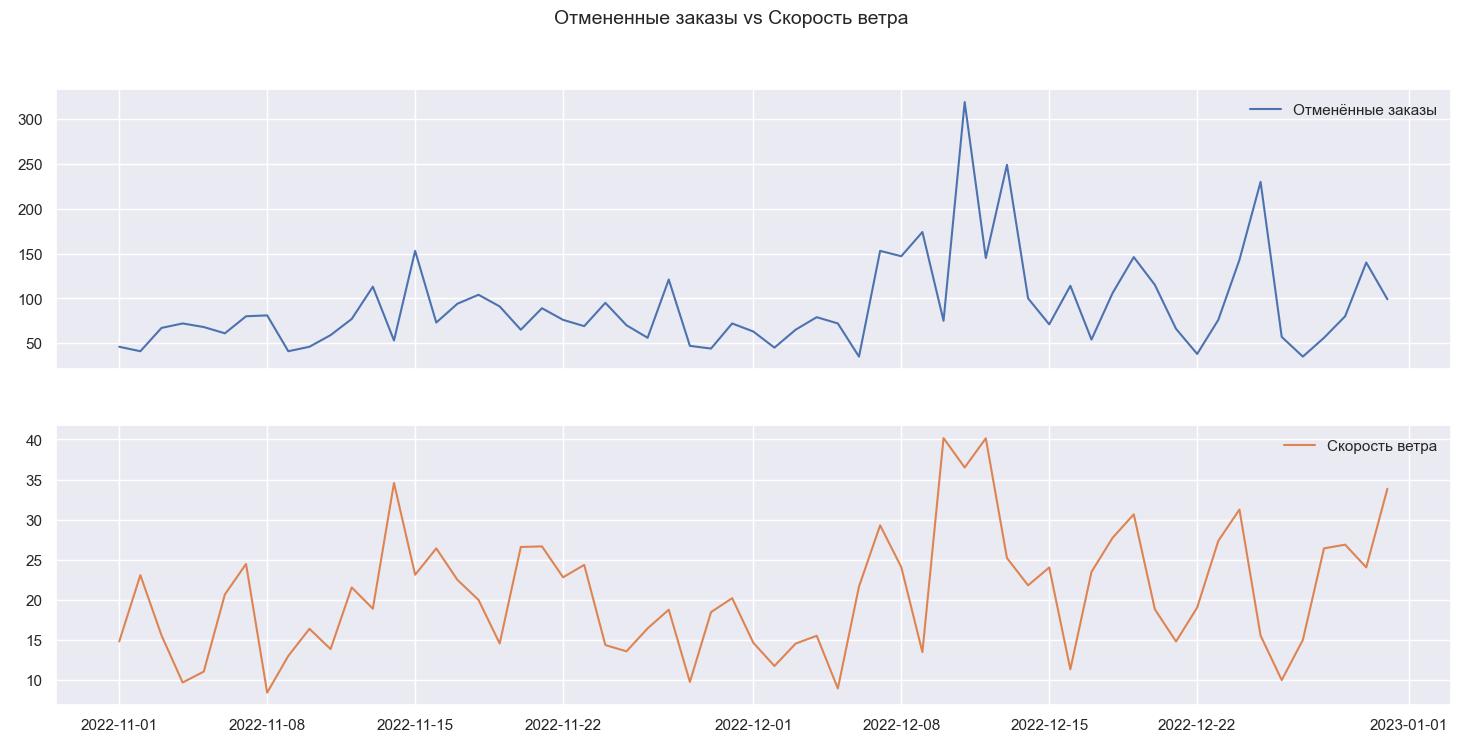

In [248]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18,8), sharex=True)
sns.lineplot(data=cancelled_weather, x='order_date', y='cancelled_orders', ax=ax1, color='#4C72B0', label='Отменённые заказы')
sns.lineplot(data=cancelled_weather, x='order_date', y='wind_speed_10m_max', ax=ax2,  color='#DD8452', label='Скорость ветра')
fig.suptitle('Отмененные заказы vs Скорость ветра', fontsize=14)
plt.show()

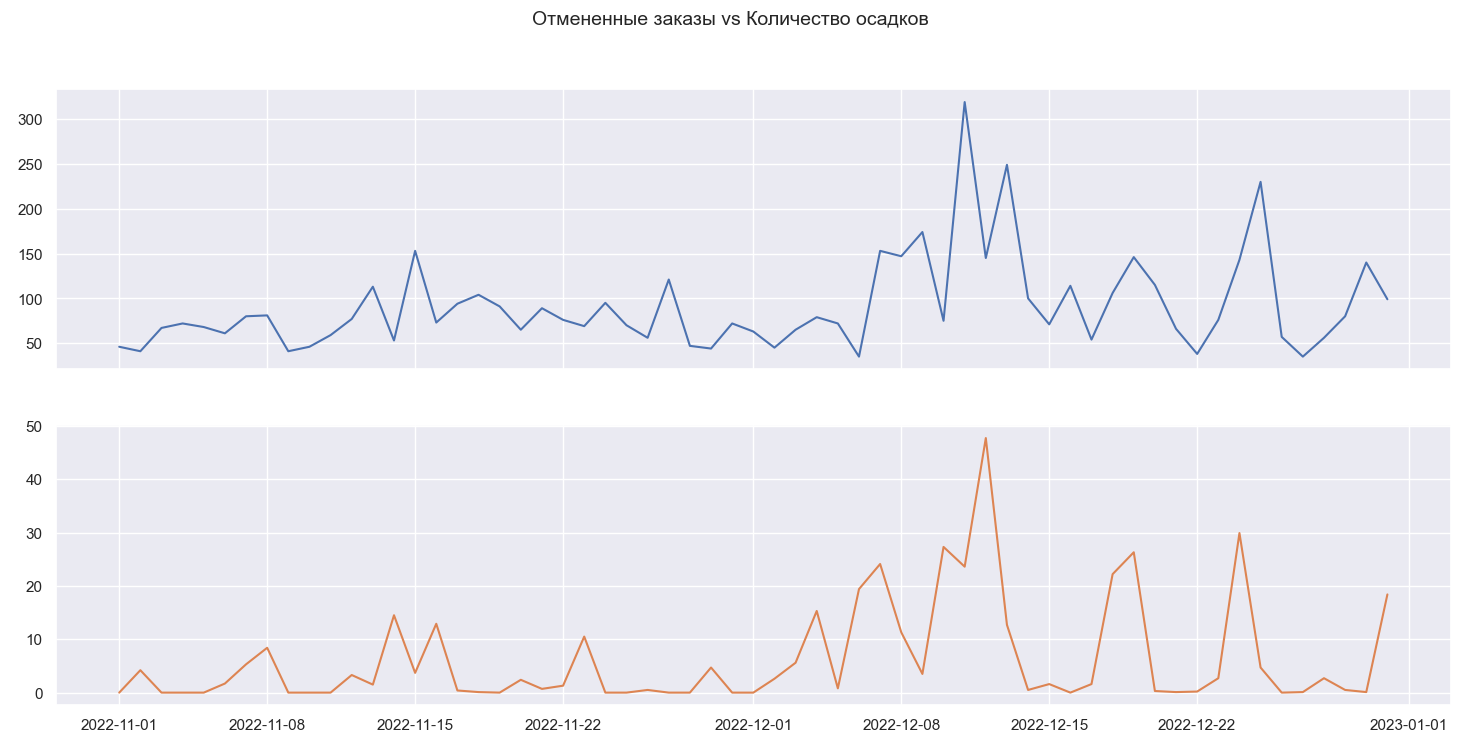

In [249]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18,8), sharex=True)
sns.lineplot(data=cancelled_weather, x='order_date', y='cancelled_orders', ax=ax1, color='#4C72B0')
sns.lineplot(data=cancelled_weather, x='order_date', y='precipitation_sum', ax=ax2, color='#DD8452')
fig.suptitle('Отмененные заказы vs Количество осадков', fontsize=14)
plt.show()

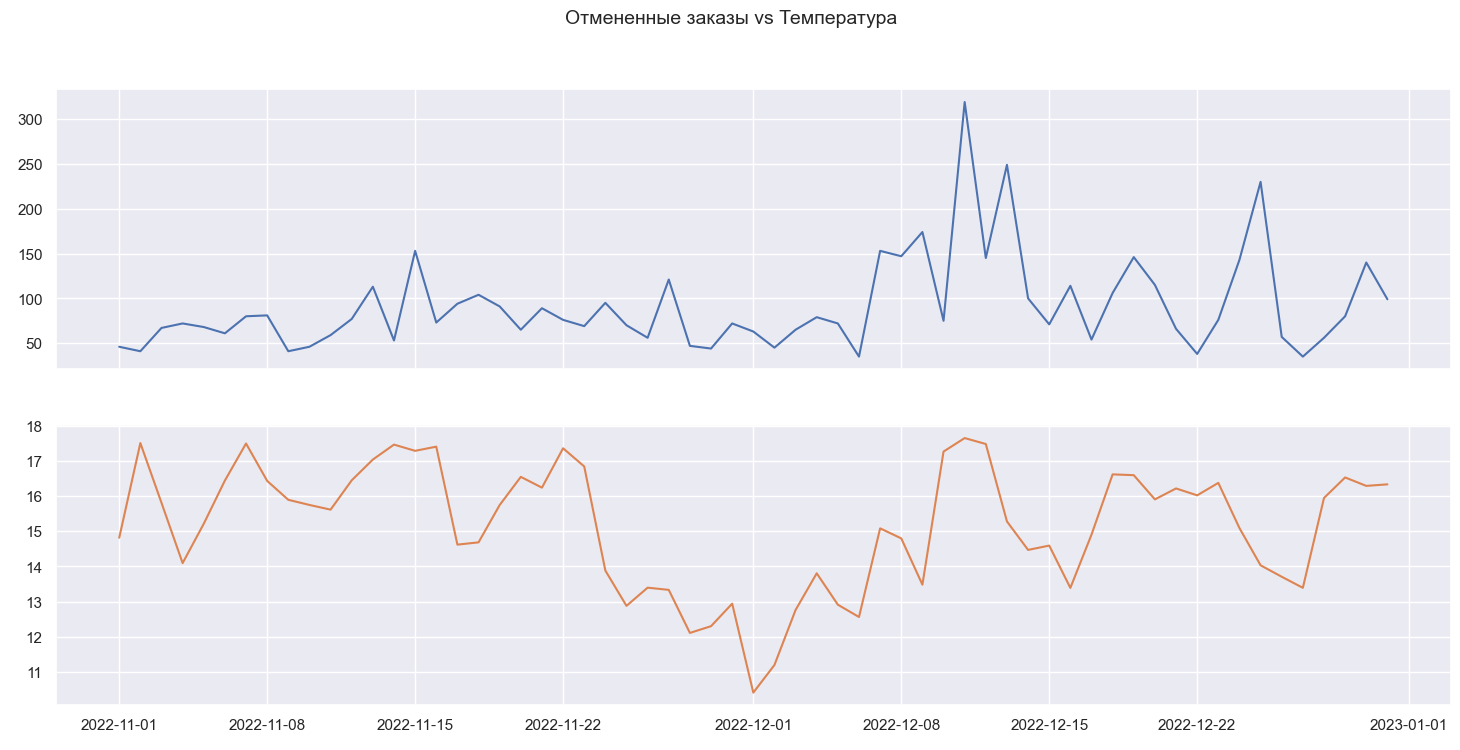

In [250]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18,8), sharex=True)
sns.lineplot(data=cancelled_weather, x='order_date', y='cancelled_orders', ax=ax1, color='#4C72B0')
sns.lineplot(data=cancelled_weather, x='order_date', y='temperature_2m_mean', ax=ax2, color='#DD8452')
fig.suptitle('Отмененные заказы vs Температура', fontsize=14)
plt.show()

In [251]:
time_weather=daily_weather.merge(orders_delivery_time, how='left', left_on='date', right_on='order_date')

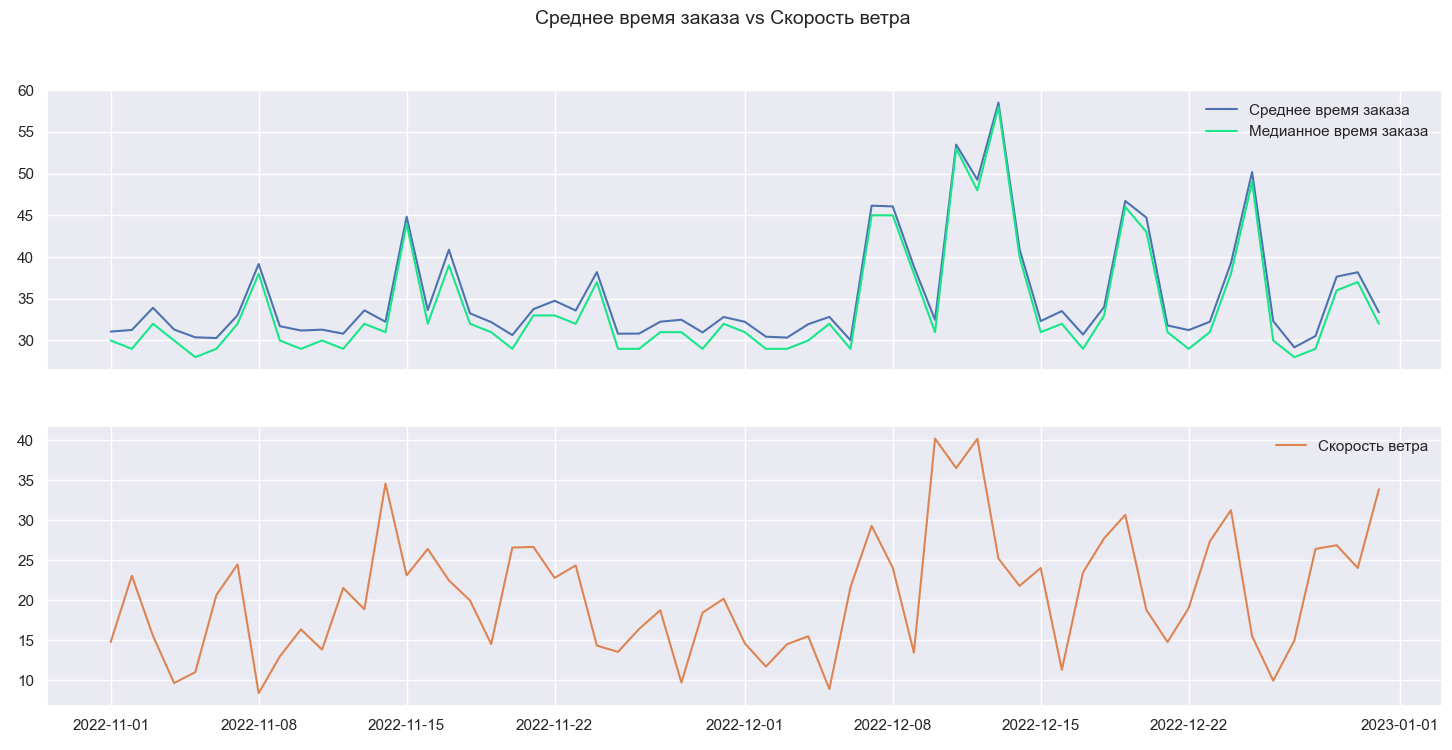

In [252]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18,8), sharex=True)
sns.lineplot(data=time_weather, x='date', y='mean', ax=ax1, color='#4C72B0', label='Среднее время заказа')
sns.lineplot(data=time_weather, x='date', y='median', ax=ax1, color="#17E789", label='Медианное время заказа')
sns.lineplot(data=time_weather, x='date', y='wind_speed_10m_max', ax=ax2,  color='#DD8452', label='Скорость ветра')
fig.suptitle('Среднее время заказа vs Скорость ветра', fontsize=14)
plt.show()

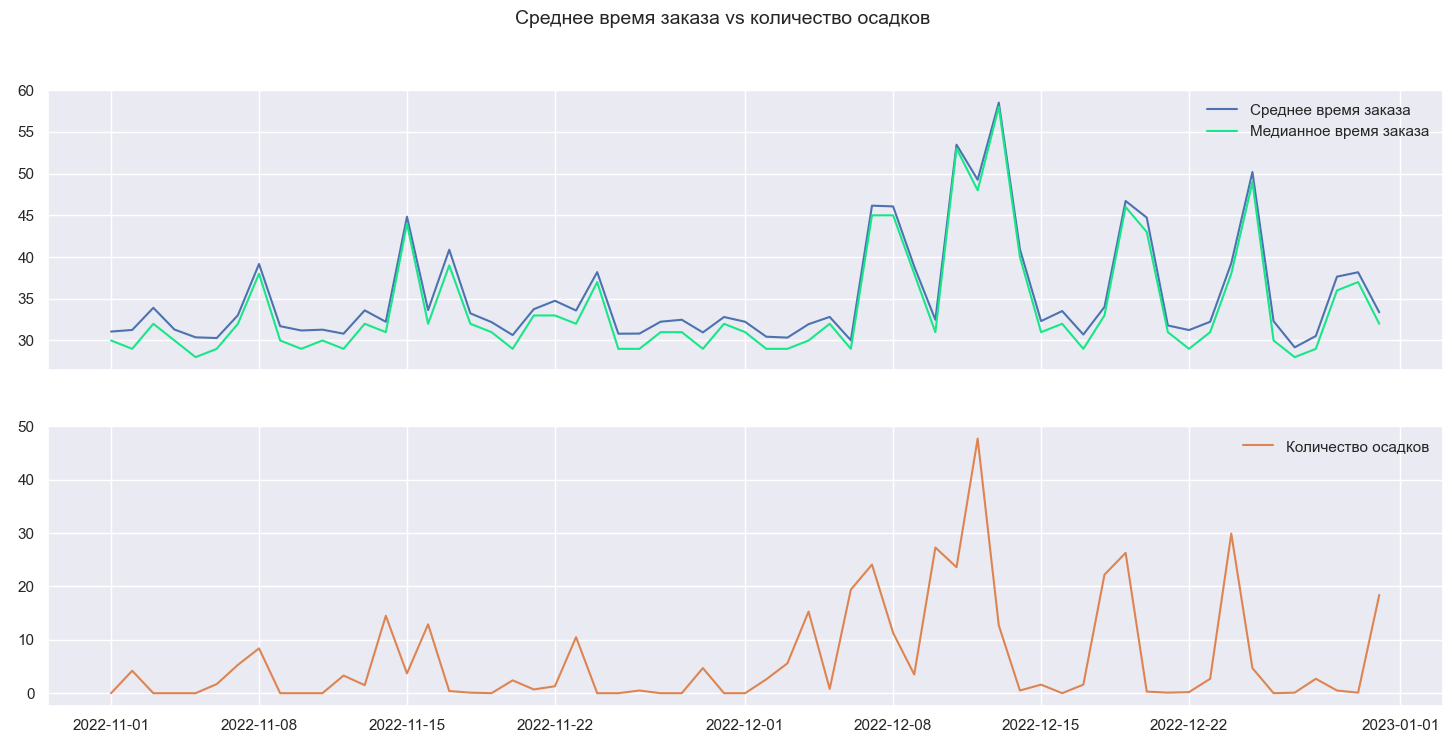

In [253]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18,8), sharex=True)
sns.lineplot(data=time_weather, x='date', y='mean', ax=ax1, color='#4C72B0', label='Среднее время заказа')
sns.lineplot(data=time_weather, x='date', y='median', ax=ax1, color="#17E789", label='Медианное время заказа')
sns.lineplot(data=time_weather, x='date', y='precipitation_sum', ax=ax2,  color='#DD8452', label='Количество осадков')
fig.suptitle('Среднее время заказа vs количество осадков', fontsize=14)
plt.show()

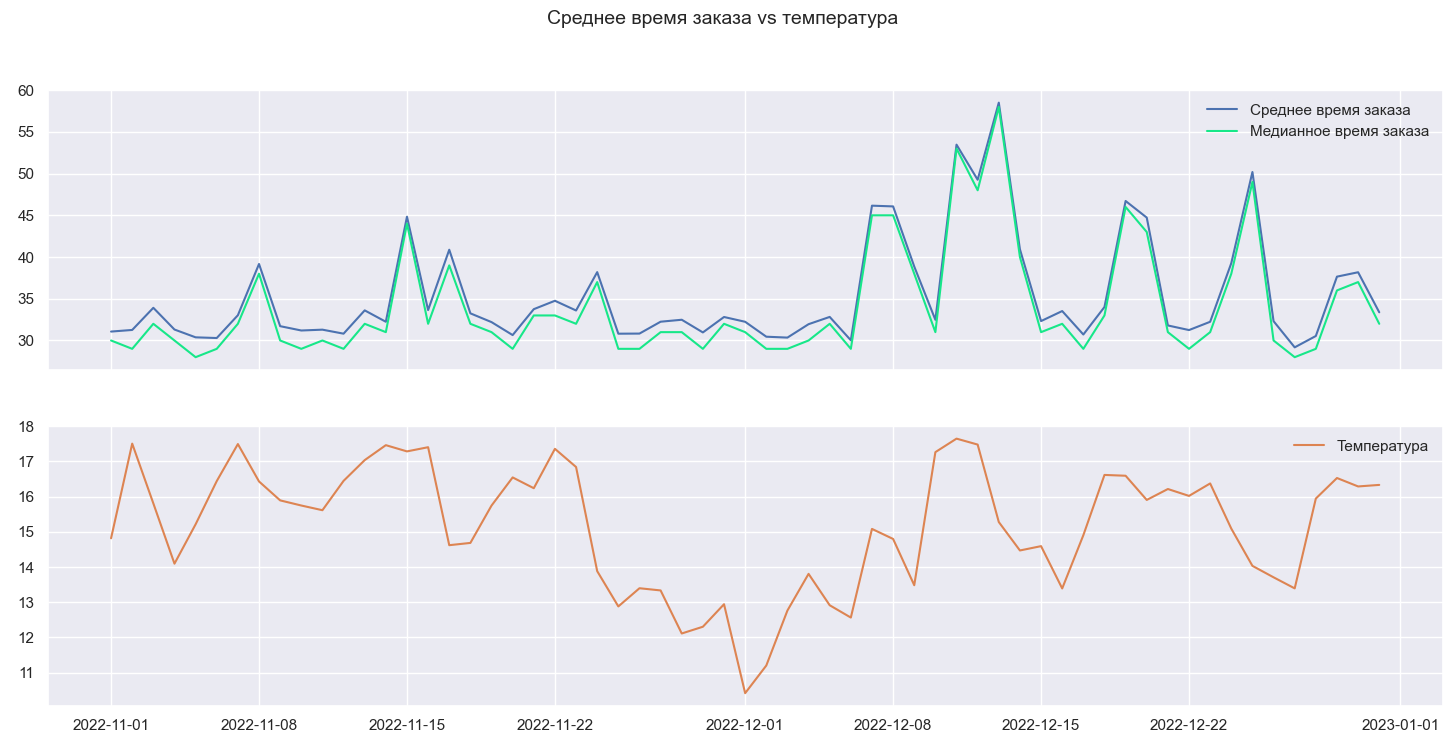

In [254]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18,8), sharex=True)
sns.lineplot(data=time_weather, x='date', y='mean', ax=ax1, color='#4C72B0', label='Среднее время заказа')
sns.lineplot(data=time_weather, x='date', y='median', ax=ax1, color="#17E789", label='Медианное время заказа')
sns.lineplot(data=time_weather, x='date', y='temperature_2m_mean', ax=ax2,  color='#DD8452', label='Температура')
fig.suptitle('Среднее время заказа vs температура', fontsize=14)
plt.show()

**На падение конверсий в дни аномалий повлияли сильный ветер и обилие осадков: видимо из-за непогоды работало мало курьеров, поэтому и назначение на заказ происходило дольше и доставка заказов осуществлялась медленнее.**

#### 8. Влияние на бизнес-результат — 3 балла
Примените один из методов декомпозиции из разобранных в первом семинаре, чтобы оценить вклад изменения конверсии и числа заказов в изменение числа доставок в декабре относительно ноября (MoM анализ).    

Постройте waterfall диаграмму.

Выпишите дни, которые внесли наибольший вклад в падение среднемесячной конверсии декабря относительно ноября. Пересекаются ли эти даты с датами повышенного числа осадков? Сделайте выводы.

In [255]:
# your code is here
orders.index = pd.to_datetime(orders.index)
orders['month_name'] = orders.index.month_name()
orders['month'] = orders.index.month
orders.tail(3)

status,cancelled,delivered,total,completion_rate,cancellation_rate,month_name,month
order_date,,,,,,,
2022-12-29,80,861,941,0.915,0.08502,December,12
2022-12-30,140,1303,1443,0.903,0.09702,December,12
2022-12-31,99,1363,1462,0.9323,0.06772,December,12


In [256]:
monthly_orders=orders.groupby(['month','month_name'], as_index=False).agg(delivered=('delivered', 'sum'), cancelled=('cancelled', 'sum'), total=('total', 'sum') )
monthly_orders

,month,month_name,delivered,cancelled,total
0,11,November,34084,2224,36308
1,12,December,35337,3347,38684


In [257]:
monthly_orders['completion_rate']=monthly_orders['delivered']/monthly_orders['total']
monthly_orders=monthly_orders.set_index('month')
monthly_orders

,month_name,delivered,cancelled,total,completion_rate
month,,,,,
11,November,34084,2224,36308,0.9387
12,December,35337,3347,38684,0.9135


In [258]:
cr_effect=np.round(monthly_orders.loc[11, 'total']*(monthly_orders.loc[12, 'completion_rate'] - monthly_orders.loc[11, 'completion_rate']), 3)
cr_effect

np.float64(-917.425)

In [259]:
orders_effect=np.round(monthly_orders.loc[11, 'completion_rate']*(monthly_orders.loc[12, 'total'] - monthly_orders.loc[11, 'total']), 3)
orders_effect

np.float64(2230.461)

In [260]:
interaction = np.round(((monthly_orders.loc[12, 'completion_rate'] - monthly_orders.loc[11, 'completion_rate'])*( monthly_orders.loc[12, 'completion_rate'] -  monthly_orders.loc[11, 'completion_rate'])),3)
interaction 

np.float64(0.001)

In [261]:
delta_deliveries = (monthly_orders.loc[12, 'delivered']  - monthly_orders.loc[11, 'delivered'])
delta_deliveries

np.int64(1253)

In [262]:
import plotly.graph_objects as go

fig = go.Figure(go.Waterfall(
    name='Декомпозиция доставок',
    orientation='v',
    measure=['absolute', 'relative', 'relative', 'relative', 'total'],
    x=['Доставки в ноябре', 'Эффект CR', 'Эффект заказов', 'Взаимодействие', 'Доставки в декабре'],
    textposition = 'outside',
    text = [monthly_orders.loc[11, 'delivered'], cr_effect, orders_effect, interaction, monthly_orders.loc[12, 'delivered']],
    y=[ monthly_orders.loc[11, 'delivered'], cr_effect, orders_effect, interaction, monthly_orders.loc[12, 'delivered']],
    connector={'line': {'color': 'gray'}}
))

fig.update_layout(
    title='Декомпозиция изменения доставок: декабрь vs ноябрь',
    yaxis_title='Число доставок',
    showlegend=False
)

fig.show()

**По этому графику можно сказать, что несмотря на то, что доля доставленных заказов в декабре снизилась (эффект CR отрицательный), но бОльшее количество заказов перекрыло этот негативный эффект и количество доставленных заказов получилось даже немного выше, чем в ноябре**.

####  9. Анализ 24/7 — 3 балла

Одним из распространенных разрезов анализа метрик продуктов с внутринедельной сезонностью является разложение по дням недели и часам. 

Постройте матрицу 24/7 (часы - дни недели) для ноября и декабря (в ячейку матрицы должно попасть агрегированное значение метрики для дня недели и часа), но перед этим очистите декабрьские значения от аномалий — для стабильной оценки нам нужны метрики без влияния экстремальной погоды.

Визуализацию стройте для:
- Числа заказов (всех);
- Completion Rate;
- Среднего или медианного времени доставки.

Подумайте, почему в определенные часы / дни недели мы наблюдаем падение конверсии? Как меняются остальные метрики?    
При ответе опирайтесь на статистические понятия — в какие-то часы просадка или, напротив, слишком высокая конверсия может быть не закономерностью, а случайностью из-за эффекта низкой базы в это время.

In [263]:
df['day_name']=df['order_time'].dt.day_name()
df['day_week']=df['order_time'].dt.day_of_week
df['hour']=df['order_time'].dt.hour
day_name_order = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']

In [264]:
df_without_anomaly=df.query('order_date!="2022-12-13"') 

In [265]:
total_orders_24_7=df_without_anomaly.groupby(['day_week','day_name', 'hour']).order_id.count().unstack().reset_index(level=['day_week']).drop('day_week', axis=1)

In [266]:
def heatmap_viz(df, title, fmt):
    plt.figure(figsize=(18,6))
    sns.heatmap(df, cmap="Blues", linewidths=0.5, linecolor='white', annot=True, fmt=fmt)
    plt.title(title)
    plt.xlabel('')
    plt.ylabel('')
    plt.show()

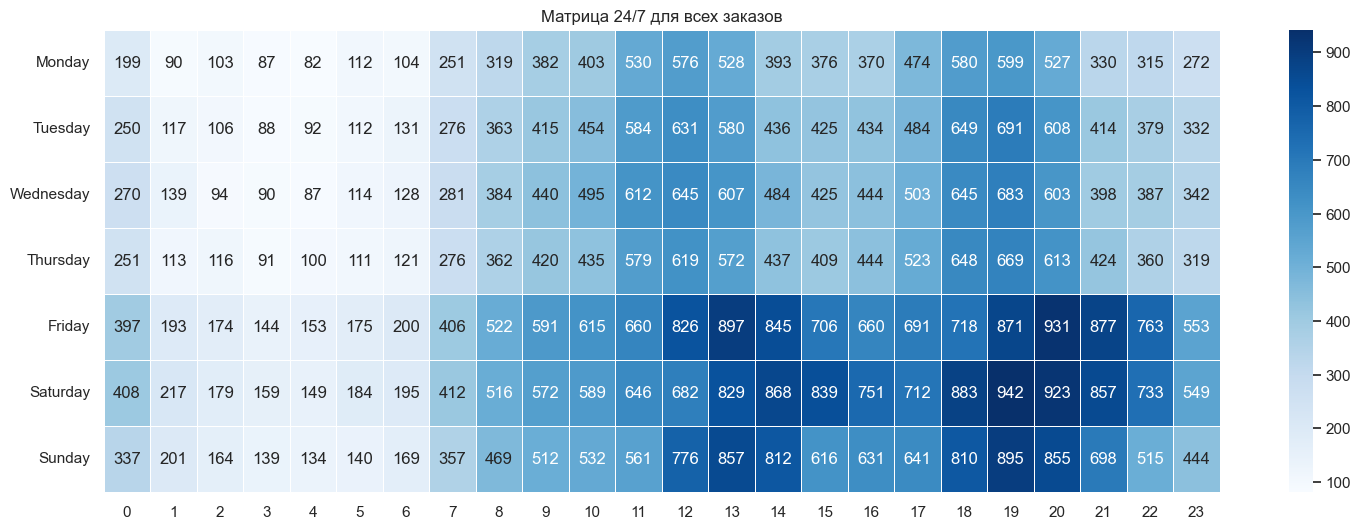

In [267]:
heatmap_viz(total_orders_24_7, 'Матрица 24/7 для всех заказов', ".0f")

In [268]:
completion_rate_24_7=df_without_anomaly.pivot_table(index=['day_week', 'day_name', 'hour'], columns='status', values='order_id', aggfunc='count')
completion_rate_24_7 = (completion_rate_24_7['delivered'] / completion_rate_24_7.sum(axis=1)).round(2).unstack().reset_index(level='day_week', drop=True)

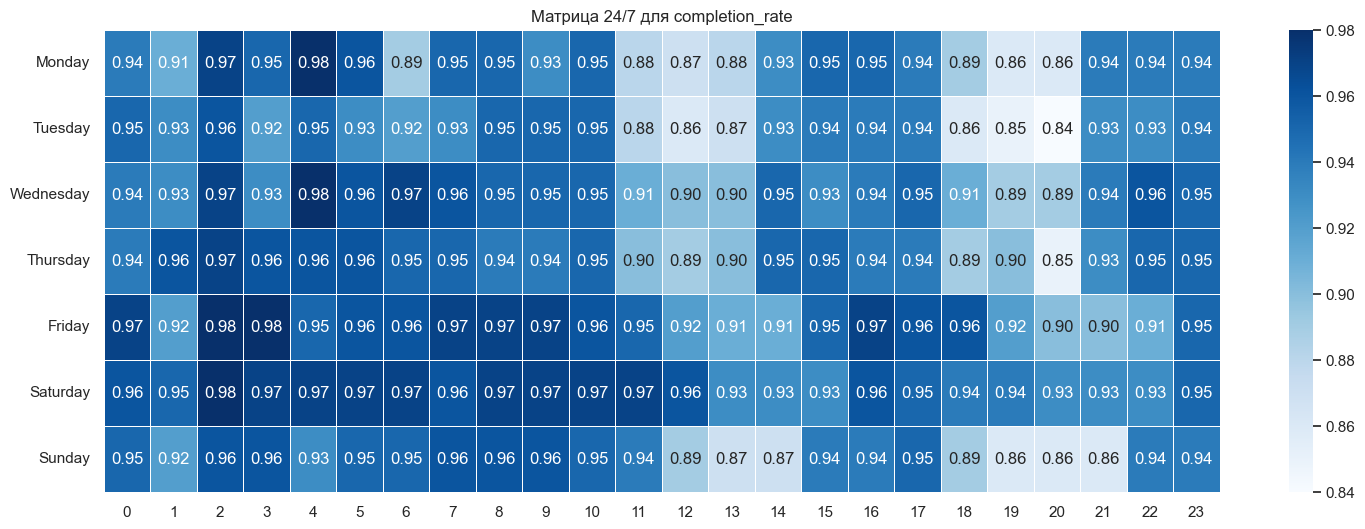

In [269]:
heatmap_viz(completion_rate_24_7, 'Матрица 24/7 для completion_rate', ".2f")

In [270]:
mean_delivery_time_24_7=df_without_anomaly.query('delivery_time.notna()').pivot_table(index=['day_week', 'day_name', 'hour'], values='order_delivery_time_min', aggfunc='mean').unstack()\
                        .reset_index(level='day_week', drop=True)
mean_delivery_time_24_7.columns = mean_delivery_time_24_7.columns.droplevel(0)

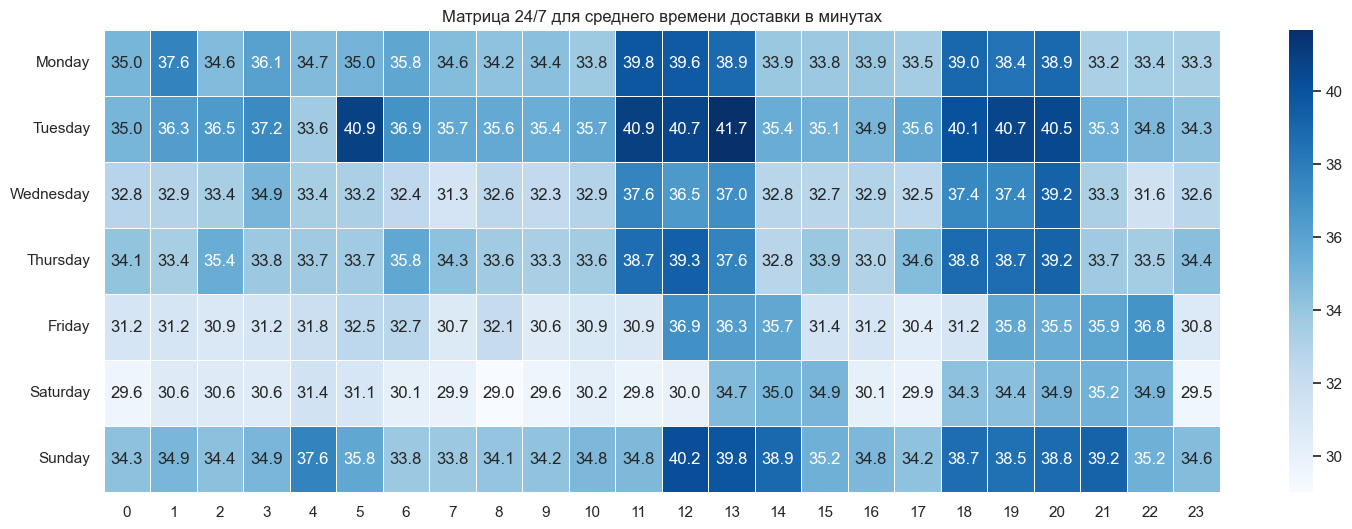

In [271]:
heatmap_viz(mean_delivery_time_24_7, 'Матрица 24/7 для среднего времени доставки в минутах', ".1f")

In [272]:
median_delivery_time_24_7=df_without_anomaly.query('delivery_time.notna()').pivot_table(index=['day_week', 'day_name', 'hour'], values='order_delivery_time_min', aggfunc='median').unstack()\
                        .reset_index(level='day_week', drop=True)
median_delivery_time_24_7.columns = median_delivery_time_24_7.columns.droplevel(0)

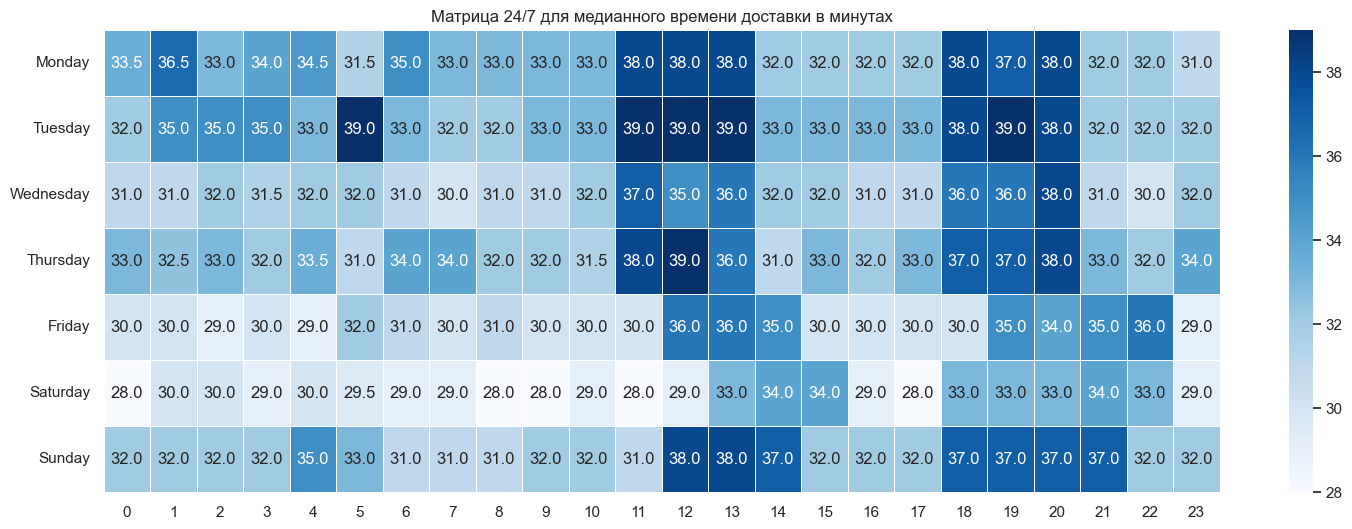

In [273]:
heatmap_viz(median_delivery_time_24_7, 'Матрица 24/7 для медианного времени доставки в минутах', ".1f")

**В целом можно заметить, что Completion Rate нижев те часы, где время доставки заказа достаточно большое от 37 минут. При этом общее количество заказов в такие часы ниже, чем в часы пик заказов. Например в пятницу вечером, заказов много, completion rate достаточно высокий, и время доставки не максимальное. А в будние с 11-13 и заказов меньше, CR ниже и время доставки одно из самых высоких. Возможно, что есть внешние причины из-за которых быстрая доставка не возможна, например пробки на дорогах в будние, а в вс многие курьеры отдыхают и не выходят на работу. И поэтому клиенты, видя, что доставка дольше обычного, отменяют заказ и тем самых роняют конверсию.**

####   10. Предложение по улучшению продукта — 3 балла
Базовым подходом для оптимизации работы в часы пик в доставке является динамическое ценообразование. В продукте эта механика еще не реализована. Вы смотрите на данные и решаете, что это отличная инициатива для планирования следующего квартала.

*Динамическое ценообразование помогает не только сглаживать часы повышенного спроса, но и регулировать работу продукта при внешних влияниях, когда пик спроса предсказать невозможно. В данном кейсе мы не рассматриваем такие решения, т.к. не стремимся написать алгоритм динамического прайсинга, а хотим провести базовое исследование проблем и поиск инициативы под быструю реализацию и тест. Поэтому в дальнейших заданиях речь идет исключительно о часах повышенного спроса, очищенных от аномалий.* 

Чтобы протестировать гипотезу, достаточно простого подхода — увеличивать стоимость доставки на фиксированный процент (например, на 20%) в определенные дни недели-часы.

- На основе построенных в предыдущем задании матриц, предложите, в какие дни недели / часы вы порекомендуете увеличить стоимость доставки.
- Для каждого месяца рассчитайте долю заказов от общего числа, который будет иметь повышенную стоимость, согласно предложенным вами правилам повышения.

**Я бы предложила увеличить доставку в часы, в которых много заказов и completion rate <= 0.9, например прежде всего в Пт и ВС: 12-15, 18-22**<br>
**Также можно было бы поэкспериментировать с доставкой в будние с 11-14 и с 18-20, но для этого надо точно понимать, что внешняя причина не помеха.**

In [274]:
November_Sunday_orders=df.query('order_month==11 and day_name in ["Friday", "Sunday"]').groupby(['hour']).order_id.count()

In [275]:
#процент заказов, которые имели бы повышенную стоимость в ноябре
(November_Sunday_orders.loc[12:14].sum()+November_Sunday_orders.loc[18:19].sum())*100/monthly_orders.loc[11,'total'] 

np.float64(10.600969483309463)

In [276]:
December_Sunday_orders=df.query('order_month==12 and day_name in ["Friday", "Sunday"]').groupby(['hour']).order_id.count()

In [277]:
#процент заказов, которые имели бы повышенную стоимость в декабре
(December_Sunday_orders.loc[12:14].sum()+December_Sunday_orders.loc[18:19].sum())*100/monthly_orders.loc[12,'total'] 

np.float64(11.524144349084892)

### Часть 2. Дизайн эксперимента

Ваше предложение понравилось команде. Бэклог инициатив собран, время планировать роадмап. Вас просят провести дизайн эксперимента повышения стоимости доставки на 20% в регулярные часы повышенного спроса, чтобы команда поняла, сколько времени понадобится для получения результатов.

#### 1. Формат эксперимента — 3 балла

Выберите и обоснуйте единицу рандомизации теста: 
- по-юзерный A/B тест,
- свитчбек по времени (например, 30-минутки);
- региональный A/B тест.

Вы отвечали на тестовый вопрос о такой же инициативе в ДЗ 3, возможно, это поможет определиться.

**Формат эксперимента - свитчбэк по времени. В датасете рассматривается только один город - Лиссабон с несколькими райнами, поэтому региональный аб тест не подходит из-за риска сетевого эффекта  между тестовой и контрольной группами. Единицей рандомизации пусть будет интервал 1 час в периоды повышенного спроса, на мой взгляд при доставке в 30-40 минут меньше дробить периоды не стоит.**

#### 2. Выбор таргет метрики — 3 балла

H1: Если мы введем динамическую наценку на доставку 20% в часы пик, то Completion Rate вырастет на 2%, а среднее время доставки снизится на 5%, потому что часть пользователей отложит заказ (снижение спроса), а повышенная оплата привлечет больше курьеров на линию (рост предложения).

Предложите таргет-метрику для эксперимента, обоснуйте свой выбор.

*Поскольку в гипотезе упоминаются сразу 2 метрики, и ни одна из них не является guardrail, метрику, которую вы не посчитаете таргетной, все равно будем учитывать в эксперименте как вторичную для принятия решения о результатах.*

**Основная таргетная переменная в этом тесте - Completion Rate, так как она напрямую отражает способность сервиса успешно выполнять заказ клиента.**
**Вторичная метрика или драйвер для принятия решения -  среднее время достаки. Метрика позволит проверить второй эффект гипотезы: сократится ли время доставки на 5% благодаря снижению спроса в часы пик.**

#### 3. Выбор guardrails метрик — 3 балла

Выберите не более 3 guardrails-метрик для эксперимента из списка ниже, обоснуйте свой выбор.

- Доля отмен заказов;
- Доля отмен заказов по причине No courier available;
- Доля отмен заказов по причине Cancelled by user;
- Среднее время на поиск курьера time_to_assign_courier_min;
- Средняя стоимость доставки;
- Средний чек;
- Среднее gross revenue на заказ (average order value + delivery fee).

*Guardrails метрик в тесте может быть больше, но нам важно понять логику ваших рассуждений при ограниченном выборе. Тут нет одного правильного ответа, будем учитывать проработку обоснования при оценке.*

**На мой взгляд в данном аб тесте необходимо контролировать следующие метрики:** <br> 
- **Доля отмен заказов** 
- **Среднее время на поиск курьера time_to_assign_courier_min**
- **Среднее gross revenue на заказ (average order value + delivery fee).** <br>
Повышение цены доставки может привести к ухудшению опыта пользователей и привести к отменам заказов. Доля отмененных заказов без разбиения на причины позволит увидеть изменение общего уровня отмен в любую сторону. Метрика Среднее время поиска курьера важна, так как данным экспериментом планируется ее уменьшить, балансируя спросом и предложением в часы пик. 
И также, я считаю, что важно отслеживать средний gross revenue для того, чтобы не допустить его падение из-за того, что пользователи увидев повышенную стоимость доставки вообще отказались сделать заказ.**

#### 4. Выбор информативных метрик — 3 балла

Выберите не более 3 информативных метрик для эксперимента из списка ниже, обоснуйте свой выбор.

- Доля отмен заказов;
- Доля отмен заказов по причине No courier available;
- Доля отмен заказов по причине Cancelled by user;
- Среднее время на поиск курьера time_to_assign_courier_min;
- Средняя стоимость доставки;
- Средний чек;
- Среднее gross revenue на заказ (average order value + delivery fee).

*Информативных метрик в тесте может быть больше, но нам важно понять логику ваших рассуждений при ограниченном выборе. Тут нет одного правильного ответа, будем учитывать проработку обоснования при оценке.*

**В качестве информативных я бы взяла следующие метрики:** <br>
- **Доля отмен заказов по причине No courier available** - метрика покажет изменилась ли ситуация с доступностью курьеров, в частности в часы пик; 
- **Средняя стоимость доставки** - метрика покажет как увеличение стоимости в некоторые периоды отразилось на фактической стоимости доставки; 
- **Доля отмен заказов по причине Cancelled by user** - метрика покажет действительно ли пользователи стали реже отменять заказы в часы пик.

#### 5. Поправка на множественное сравнение — 3 балла

Перед тем, как приступить к расчету длительности, выберите уровень значимости и мощность, которые будете использовать в расчетах далее. Отталкивайтесь от общепринятых alpha = 0.05 и beta = 0.2.

Для поправки на множественное сравнение можете взять поправку Бонферрони. Не забывайте, что мы корректируем alpha только на число метрик, непосредственно участвующих в принятии решения об успешности теста.

**По методу бонферрони поделю alpha на 5, так как в нашем экспериименте 2 таргетные метрики + 3 guardrail метрики. -> alpha=0.01**

#### 6. Влияние выбросов на длительность эксперимента — 3 балла

В исследовательской части мы обнаружили аномальные значения метрик, вызванные внешними факторами. Такое состояние продукта не является целевым и случается достаточно редко.

На примере таргет метрики оцените дисперсию метрики, рассчитанную на значениях **декабря** полностью и с исключением аномального дня. Для исключения можете использовать **один** из подходов: удалить аномальный день или заменить его на другой не аномальный. Обоснуйте свой выбор.

Мы проводим эти расчеты в рамках дизайна эксперимента, поэтому в анализе используйте формулу (подсказки по формулам в задании ниже), которую будете применять для расчета длительности (ratio метрика, рассчитанная по единице рандомизации эксперимента).

Сделайте выводы о вариативности метрики при включении / исключении аномалии. Напишите, как разные подходы повлияют на длительность эксперимента и почему. Примите решение, какой из способов расчета будете применять вы в следующих шагах.

In [278]:
orders.head(3)

status,cancelled,delivered,total,completion_rate,cancellation_rate,month_name,month
order_date,,,,,,,
2022-11-01,46,963,1009,0.9544,0.04559,November,11
2022-11-02,41,952,993,0.9587,0.04129,November,11
2022-11-03,67,925,992,0.9325,0.06754,November,11


In [279]:
#дисперсия Completion rate за весь декабрь
print('Дисперсия с аномальным днем: ', np.var(orders[orders['month']==12]['completion_rate'], ddof=1))

Дисперсия с аномальным днем:  0.0027185428956788874


In [280]:
#Исключение 2022-12-13 в расчете дисперсии:
print('Дисперсия без аномального дня (удаление): ', np.var(orders[orders['month']==12].drop('2022-12-13', axis=0)['completion_rate'], ddof=1))

Дисперсия без аномального дня (удаление):  0.0020658753636996104


In [281]:
#можно предположить, что некий средний день обладает средней Completion rate, и тогда подставив среднее значение CR вместо аномального посчитаю дисперсию:
mean_CR_dec=orders[orders['month']==12].drop('2022-12-13', axis=0)['completion_rate'].mean()
orders.loc['2022-12-13', 'completion_rate']=mean_CR_dec
print('Дисперсия с заменой CR аномального дня на среднее значение: ', np.var(orders[orders['month']==12]['completion_rate'], ddof=1))

Дисперсия с заменой CR аномального дня на среднее значение:  0.00199701285157629


**Как видно из расчетов выше, аномальный день было бы лучше заменить на обычный день, характериный для данного периода. Если в датасете был бы декабрь прошлого года с неаномальным днем 13 декабря, то я взяла бы его. Также думала взять один из ближайших дней текущего декабря, но так как разница в дисперсиях при удалении и замене аномального дня не слишком велика, и я уже устала решать этот проект, то я решила продолжить без замены аномального дня и просто удалила 2022-12-13. Решила удалить именно этот один день, так как он является аномальным с точки зрения проверок метрик, отражающих качество работы сервиса.**

#### 7. Длительность эксперимента — 3 балла

Рассчитайте длительность теста для выбранных **таргет и вторичной метрик** принятия решений. 

Обратите внимание, что обе метрики — ratio, используйте подходы для работы с данным типом метрик.

---
**Формулы расчета объёма выборки через MDE для разных метрик**

**Для среднего**

$$
n \;=\; \frac{2\,\sigma^2 \,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$


**Для доли** (бинарная метрика)

$$
n \;\\=\;\; \frac{2\,p(1-p)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$

**Для Ratio-метрики дельта-методом**

$$
\mathrm{Var}\!\left(\tfrac{X}{Y}\right) \;\approx\; 
\frac{1}{\mu_Y^2}\,\mathrm{Var}(X) 
\;+\; \frac{\mu_X^2}{\mu_Y^4}\,\mathrm{Var}(Y) 
\;-\; 2\,\frac{\mu_X}{\mu_Y^3}\,\mathrm{Cov}(X,Y)
$$

тогда

$$
n \;=\; \frac{2 \cdot \mathrm{Var}\!\left(\tfrac{X}{Y}\right)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$

**Для линеаризованной Ratio-метрики**   
Переходим для каждой единицы рандомизации к линеаризованной версии метрики:

$$
Z_i \;=\; \frac{\overline X}{\overline Y} \;+\; \frac{1}{\overline Y}\!\left( X_i \;-\; \frac{\overline X}{\overline Y}\, Y_i \right).
$$

тогда

$$
n \;=\; \frac{2 \cdot \mathrm{Var}(Z)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}.
$$


Для всех способов:
- Формулы указаны для групп одинакового размера (50/50) и двустороннего критерия;
- n — размер одной группы.

**Расчет для основной таргетной метрики - Completion rate**

In [282]:
df_without_anomaly.head(3)

,order_id,order_time,delivery_time,status,cancellation_reason,order_value,delivery_fee,estimated_delivery_time_min,time_to_assign_courier_min,actual_preparation_time_min,...,user_id,user_segment,order_date,delivery_date,order_month,order_month_name,order_delivery_time_min,day_name,day_week,hour
0,257,2022-11-01 00:01:46,2022-11-01 00:21:52,delivered,NaN,25.73,2.09,27.0,10.2,15.1,...,5737,returning,2022-11-01,2022-11-01,11,November,20.0,Tuesday,1,0
1,165,2022-11-01 00:06:07,2022-11-01 00:27:01,delivered,NaN,22.0,0.77,13.0,9.0,15.9,...,4095,new,2022-11-01,2022-11-01,11,November,20.0,Tuesday,1,0
3,904,2022-11-01 00:06:48,2022-11-01 00:36:42,delivered,NaN,40.49,2.02,27.0,3.7,16.0,...,1773,returning,2022-11-01,2022-11-01,11,November,29.0,Tuesday,1,0


In [283]:
#я поняла так, что считать нужно только по данным за декабрь
december_orders=df_without_anomaly[df_without_anomaly['order_month']==12].pivot_table(index=['day_week','day_name', 'hour'], columns='status', values='order_id', aggfunc='count', 
                                                                                      margins=True, margins_name='total')[:-1]

In [284]:
december_orders.head()

status                  cancelled  delivered  total
day_week day_name hour                             
0        Monday   0             5         86     91
                  1             4         48     52
                  2             1         46     47
                  3             1         46     47
                  4             1         41     42

In [285]:
#Функция для линеаризации метрики:
def ratio_linearise(num, den):
    num_mean = np.mean(num)
    den_mean = np.mean(den)
    z_lin = num_mean / den_mean + 1 / den_mean * (num - num_mean*den / den_mean )
    
    return z_lin

In [286]:
#линеаризация Completion Rate:
linear_CR=ratio_linearise(december_orders['delivered'], december_orders['total'])

In [287]:
#mde для Completion rate: 
mde_CR=0.02*december_orders['delivered'].sum()/december_orders['total'].sum()
mde_CR

np.float64(0.01826956881397994)

In [288]:
#дисперсия линеаризированной метрики Completion Rate:
var_linear_CR=np.var(linear_CR, ddof=1)
var_linear_CR

0.003009393600662189

In [289]:
def get_n(var_liner_metric, metric_mde):

    alpha=0.01
    beta=0.2

    z_alpha = norm.ppf(1 - alpha/2)
    z_beta = norm.ppf(1 - beta)

    #размер выборки в единицах рандомизации:
    n = 2*var_liner_metric*(z_alpha+ z_beta)**2/ metric_mde**2

    print(f"Размер выборки на группу: {np.ceil(n):.0f}")
    print(f"Общий размер выборки: {2 * np.ceil(n):.0f}")

    return np.ceil(n)

In [290]:
#размер групп
n_CR=get_n(var_linear_CR, mde_CR)

Размер выборки на группу: 211
Общий размер выборки: 422


**Расчет для второй таргетной метрики - среднее время достаки**

In [291]:
december_times=df_without_anomaly[(df_without_anomaly['order_month']==12) & (df_without_anomaly['delivery_time'].notna())].groupby(['day_week','day_name', 'hour'])\
                        .agg(delivery_time_sum=('order_delivery_time_min', 'sum'),orders_count=('order_id', 'count'), assign_time_sum=('time_to_assign_courier_min', 'sum'))

In [292]:
linear_mean_delivery_time=ratio_linearise(december_times['delivery_time_sum'], december_times['orders_count'])
linear_mean_delivery_time.head()

day_week  day_name  hour
0         Monday    0      37.92
                    1       37.8
                    2      37.24
                    3      37.32
                    4      37.03
dtype: float64

In [293]:
mde_mean_delivery_time=0.05*december_times['delivery_time_sum'].sum()/december_times['orders_count'].sum()
mde_mean_delivery_time

np.float64(1.8420196960692758)

In [294]:
var_linear_mean_delivery_time=np.var(linear_mean_delivery_time, ddof=1)
var_linear_mean_delivery_time

21.270408343317676

In [295]:
n_delivery_time=get_n(var_linear_mean_delivery_time, mde_mean_delivery_time)

Размер выборки на группу: 147
Общий размер выборки: 294


In [296]:
#Итого n - единиц рандомизации, у меня это 1 час, для двух групп будет:
n=max(n_CR, n_delivery_time)*2
n

np.float64(422.0)

In [297]:
#Я поняла Ангелину так, что нужно считать не по пиковым часам, а по общему количеству часов доставки в день, и тогда тест будет длиться следующее количество недель:
n_weeks=np.ceil(n/(24*7)) 
n_weeks

np.float64(3.0)

**Итого, длительность теста определяется по той метрики, для которой требуется больше времени, а именно в нашем случае для Completion rate. Так как в следующем пункте требуется целое число дней кратное 7, то я перевела длительность теста в недели.**

#### 8. MDE для guardrails метрик — 3 балла

У нас нет информации по допустимым отрицательным эффектам для выбранных guardrails метрик, поступим обратным образом — рассчитайте минимальный детектируемый эффект для guardrails-метрик, используя максимальную длительность, полученную на предыдущем шаге (число дней целое и должно быть кратно 7 из-за недельной сезонности продукта). 

Не забывайте, что в этом пункте вы тоже можете работать с ratio-метриками.

In [298]:
#Функция для расчета mde метрик:
def mde_from_n(metric_series, n_group, alpha=0.01, power=0.8, two_sided=True):
    var = np.var(metric_series, ddof=1)
    z_alpha = norm.ppf(1 - alpha/2) if two_sided else norm.ppf(1 - alpha)
    z_beta = norm.ppf(power)
    return np.sqrt(2 * var * (z_alpha + z_beta) ** 2 / n_group)

In [299]:
#умножаю на 24 так как доставка осуществляется 24/7, а значит единиц рандомизации у нас 24 и тогда n на группу за 3 недели теста будет:
n_group=24*n_weeks*7/2
n_group


np.float64(252.0)

**Выбранные guardrail метрики:** <br> 
- **Доля отмен заказов** 
- **Среднее время на поиск курьера time_to_assign_courier_min**
- **Среднее gross revenue на заказ (average order value + delivery fee).** <br>

In [300]:
december_orders.head()

status                  cancelled  delivered  total
day_week day_name hour                             
0        Monday   0             5         86     91
                  1             4         48     52
                  2             1         46     47
                  3             1         46     47
                  4             1         41     42

In [301]:
#линеаризация метрики - Доля отмененных заказов:
linear_CancelRate=ratio_linearise(december_orders['cancelled'], december_orders['total'])
#расчет mde:

mde_Canc_Rate=mde_from_n(linear_CancelRate, n_group)
mde_Canc_Rate*100 #умножила на 100, чтобы увидеть процент измения метрики

np.float64(1.6701537825827866)

In [302]:
december_times.head()

delivery_time_sum  orders_count  assign_time_sum
day_week day_name hour                                                  
0        Monday   0             3.395e+03            86            734.5
                  1              1.97e+03            48            436.5
                  2             1.778e+03            46            403.0
                  3             1.795e+03            46            366.3
                  4              1.55e+03            41            344.9

In [303]:
#расчет для метрики  Среднее время на поиск курьера:
linear_assign_time=ratio_linearise(december_times['assign_time_sum'], december_times['orders_count'])
mde_assing_time=mde_from_n(linear_assign_time, n_group)
mde_assing_time*100

np.float64(17.80622898979363)

In [304]:
#расчет для метрики Среднее gross revenue на заказ (average order value + delivery fee)
df_without_anomaly['gross_order_revenue']=df_without_anomaly['order_value']+df_without_anomaly['delivery_fee']
december_gross_order_revenue=df_without_anomaly.query('status!="cancelled"').groupby(['day_week','day_name', 'hour']).agg(order_revenue_sum=('gross_order_revenue', 'sum'),orders_count=('order_id', 'count'))
december_gross_order_revenue.head()

order_revenue_sum  orders_count
day_week day_name hour                                 
0        Monday   0             4.939e+03           188
                  1             2.239e+03            82
                  2             2.875e+03           100
                  3             2.211e+03            83
                  4             2.229e+03            80

In [305]:
gross_order_revenue_linear=ratio_linearise(december_gross_order_revenue['order_revenue_sum'],december_gross_order_revenue['orders_count'])
mde_gross_revenue=mde_from_n(gross_order_revenue_linear, n_group)
mde_gross_revenue*100

np.float64(13.831121536140811)

**сомневаюсь в правильности своих расчетов. mde кажется высоким, относительно заложенного в гипотезе эффекта для таргет метрики.** 

#### 9. MDE для информативных метрик — 3 балла

Рассчитайте MDE для выбранных информативных метрик также, как рассчитывали для guardrails.

Не забывайте, что в этом пункте вы тоже можете работать с ratio-метриками.

**Информативные метрики:** <br>
- **Доля отмен заказов по причине No courier available**
- **Средняя стоимость доставки**
- **Доля отмен заказов по причине Cancelled by user**

In [306]:
december_cancelled_orders=df_without_anomaly.query('status=="cancelled" and order_month==12').pivot_table(index=['day_week', 'hour'], columns='cancellation_reason', values='order_id', aggfunc='count',
                                                                                                          margins=True, margins_name='total').fillna(0)[:-1]

In [307]:
december_cancelled_orders.head()

cancellation_reason  Cancelled by user  No courier available  total
day_week hour                                                      
0        0                         5.0                   0.0      5
         1                         4.0                   0.0      4
         2                         1.0                   0.0      1
         3                         0.0                   1.0      1
         4                         1.0                   0.0      1

In [308]:
#расчет для метрики Доля отмененных заказов по причине Cancelled by user":
linear_cancelled_by_user=ratio_linearise(december_cancelled_orders['Cancelled by user'], december_cancelled_orders['total'])
mde_cancelled_by_user_rate=mde_from_n(linear_cancelled_by_user, n_group)
mde_cancelled_by_user_rate*100

np.float64(6.686033272884602)

In [309]:
#расчет для метрики Доля отмененных заказов по причине No courier available:
linear_no_courier=ratio_linearise(december_cancelled_orders['No courier available'], december_cancelled_orders['total'])
mde_linear_no_courie_rate=mde_from_n(linear_no_courier, n_group)
mde_linear_no_courie_rate*100

np.float64(6.686033272884602)

In [310]:
#расчет для метрики средняя стоимость доставки:
december_delivery_fee=df_without_anomaly.query('status!="cancelled"').groupby(['day_week','day_name', 'hour']).agg(delivery_fee_sum=('delivery_fee', 'sum'),orders_count=('order_id', 'count'))
december_delivery_fee.head()

delivery_fee_sum  orders_count
day_week day_name hour                                
0        Monday   0                414.7           188
                  1                189.5            82
                  2                205.3           100
                  3                179.3            83
                  4                167.6            80

In [311]:
linear_delivery_fee=ratio_linearise(december_delivery_fee['delivery_fee_sum'], december_delivery_fee['orders_count'])
mde_delivery_fee=mde_from_n(linear_delivery_fee, n_group)
mde_delivery_fee*100

np.float64(10.333365484047432)

#### 10. Правило принятия решения — 3 балла

Сформулируйте условия, при которых эксперимент считается успешным. Ваш ответ должен учитывать таргет-метрику, вторичную и guardrails.

Мы разбирали возможные варианты принятия решения об успешности в Лекции 3, можете использовать идеи оттуда.

**Эксперимент считается успешным, если все метрики значимы в нужную сторону (увеличение Completion rate, уменьшение среднего времени и так далее). Также считаю, что эксперимент будет успешным, если значимый положительный эффект будет наблюдаться только у Completion rate, а среднее время значимо не изменится. При этом gurdrail не должны иметь значимых отрицательных эффектов. То есть я думаю, что сервис устроит ситуация, при которой доля успешно доставленных заказов вырастет, а все остальные метрики останутся примерно на таком же уровне, так как именно успешная доставка является основной ценностью, которая приносит прибыль компании.**<br>
**Если Completion rate значимо не изменится ни в одну из сторон, а остальные метрики изменятся значимо в нужную сторону, то думаю, что в этом случае нужно будет посмотреть на размер эффекта (например, среднее время доставки уменьшилось на треть; количество заказов выросло и за ним выросло gross revenue, но при этом пропорции доставленных и отменных заказов остались теже) и если он существенно улучшает качество сервиса, то можно предложить бизнесу выкатить изменения.** 